# BÁO CÁO THỰC HÀNH CHUYÊN SÂU: PRE-TRAINED MODELS, TRANSFER LEARNING & FINE-TUNING TRÊN CIFAR-10

**Học phần:** Deep Learning & Computer Vision  
**Chủ đề:** Khảo sát, Thực nghiệm và Đánh giá Học chuyển giao (Transfer Learning) và Tinh chỉnh (Fine-Tuning) với ResNet-18 và DenseNet-121  
**Môi trường thực nghiệm:** PyTorch, Torchvision, TensorBoard, Môi trường tính toán CPU-First  
**Tiêu chuẩn thực hiện:** Source-First, Design-First, Test-Driven, Reproducible  

---

## MỤC LỤC TỔNG QUAN (TABLE OF CONTENTS)
- [PHẦN 1. Giới Thiệu & Cơ Sở Lý Thuyết (Introduction & Theoretical Background)](#phần-1-giới-thiệu--cơ-sở-lý-thuyết-introduction--theoretical-background)
- [PHẦN 2. Phân Tích Yêu Cầu & Thiết Kế Hệ Thống (Requirements & System Design)](#phần-2-phân-tích-yêu-cầu--thiết-kế-hệ-thống-requirements--system-design)
- [PHẦN 3. Môi Trường & Chuẩn Bị Dữ Liệu (Environment & Data Preparation)](#phần-3-môi-trường--chuẩn-bị-dữ-liệu-environment--data-preparation)
- [PHẦN 4. Tiền Xử Lý Dữ Liệu (Data Preprocessing)](#phần-4-tiền-xử-lý-dữ-liệu-data-preprocessing)
- [PHẦN 5. Xây Dựng Mô Hình (Model Development)](#phần-5-xây-dựng-mô-hình-model-development)
- [PHẦN 6. Thiết Kế Thực Nghiệm & Huấn Luyện (Experiment Design & Training)](#phần-6-thiết-kế-thực-nghiệm--huấn-luyện-experiment-design--training)
- [PHẦN 7. Đánh Giá & Phân Tích Kết Quả (Evaluation & Results Analysis)](#phần-7-đánh-giá--phân-tích-kết-quả-evaluation--results-analysis)
- [PHẦN 8. Kiểm Thử & Xác Minh (Testing & Validation)](#phần-8-kiểm-thử--xác-minh-testing--validation)
- [PHẦN 9. Suy Luận & Sử Dụng Mô Hình (Inference & Usage)](#phần-9-suy-luận--sử-dụng-mô-hình-inference--usage)
- [PHẦN 10. Quản Lý Mã Nguồn & Tái Lập (Version Control & Reproducibility)](#phần-10-quản-lý-mã-nguồn--tái-lập-version-control--reproducibility)
- [PHẦN 11. Kết Quả, Hạn Chế & Hướng Phát Triển (Conclusion & Future Work)](#phần-11-kết-quả-hạn-chế--hướng-phát-triển-conclusion--future-work)
- [PHẦN 12. Tài Liệu & Phụ Lục (References & Appendices)](#phần-12-tài-liệu--phụ-lục-references--appendices)
- [PHẦN 13. Quy Trình Sử Dụng AI (AI Usage & Prompting Log)](#phần-13-quy-trình-sử-dụng-ai-ai-usage--prompting-log)


---
# PHẦN 1. Giới Thiệu & Cơ Sở Lý Thuyết (Introduction & Theoretical Background)

### 1.1. Tổng quan bài toán và bối cảnh thực hiện
Trong thị giác máy tính, phân loại ảnh là bài toán cơ sở đóng vai trò nền tảng cho nhiều tác vụ phức tạp như nhận diện đối tượng, phân vùng ngữ nghĩa và tái tạo 3D. Việc huấn luyện mạng nơ-ron tích chập sâu (Deep CNN) từ đầu (from scratch) trên các tập dữ liệu vừa và nhỏ thường gặp hai vấn đề lớn:
1. **Hiện tượng quá khớp (Overfitting):** Số lượng mẫu huấn luyện có hạn không đủ để tối ưu hóa hàng triệu trọng số tự do, khiến mô hình chỉ ghi nhớ nhiễu thay vì học các đặc trưng khái quát.
2. **Chi phí tính toán khổng lồ:** Việc hội tụ từ khởi tạo ngẫu nhiên đòi hỏi hàng triệu lượt lặp qua dữ liệu lớn, tiêu tốn năng lượng và thời gian tính toán kéo dài.

Bộ dữ liệu **CIFAR-10** (gồm 60.000 ảnh màu kích thước $32 \times 32$ pixels thuộc 10 lớp) là bài toán kiểm thử tiêu chuẩn để đánh giá khả năng chuyển giao tri thức từ các mô hình học sâu hiện đại được tiền huấn luyện trên tập dữ liệu quy mô lớn **ImageNet-1K** (1.28 triệu ảnh, 1.000 lớp).

### 1.2. Mục tiêu, phạm vi và yêu cầu dự án
* **Mục tiêu khoa học:**
  - Khảo sát thực nghiệm và làm sáng tỏ sự khác biệt cơ bản giữa hai chiến lược thích nghi: **Học chuyển giao (Transfer Learning / Feature Extraction)** và **Tinh chỉnh (Fine-Tuning)**.
  - Đo lường và so sánh đối chứng hiệu năng giữa hai họ kiến trúc mạng sâu tiêu biểu: mạng dư học sâu (**ResNet-18**) và mạng kết nối dày đặc (**DenseNet-121**).
  - Khảo sát sự nhạy cảm của mô hình đối với các siêu tham số quan trọng: Tốc độ học (Learning Rate: $10^{-3}$ vs $10^{-4}$) và Kích thước batch (Batch Size: $16$ vs $32$).
* **Phạm vi và yêu cầu:**
  - Tối ưu hóa chu trình thực thi trên môi trường máy tính cá nhân CPU-First (Intel Core i5, không đòi hỏi card đồ họa rời GPU).
  - Xây dựng hệ thống module hóa hoàn chỉnh, đáp ứng tiêu chuẩn kiểm thử tự động, tái lập kết quả và theo dõi thời gian thực qua TensorBoard.

### 1.3. Đầu vào, đầu ra và tiêu chí đánh giá
* **Dữ liệu đầu vào (Input):** Ảnh màu RGB $32 \times 32 \times 3$, được nội suy phóng đại lên $128 \times 128 \times 3$ và chuẩn hóa theo phân phối thống kê ImageNet.
* **Dữ liệu đầu ra (Output):** Vector logits và phân phối xác suất 10 chiều tương ứng với 10 lớp: `airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, `truck`.
* **Tiêu chí đánh giá định lượng:**
  - Hàm mất mát Cross-Entropy Loss.
  - Độ chính xác tổng thể (Top-1 Accuracy) trên tập Train, Validation và Test.
  - Độ chính xác theo từng lớp riêng biệt (Per-class Accuracy).
  - Ma trận nhầm lẫn (Confusion Matrix) để phân tích các cặp nhầm lẫn phổ biến.
  - Hiệu quả tài nguyên: Tỷ lệ tham số có thể huấn luyện (Trainable Parameters) và thời gian thực thi trung bình mỗi epoch.

### 1.4. Cơ sở lý thuyết liên quan đến bài toán
* **Bản chất của biểu diễn đặc trưng phân cấp:**
  Các tầng tích chập nông học các bộ lọc phát hiện cạnh, góc, viền và kết cấu màu sắc mang tính phổ quát cho mọi loại ảnh. Các tầng tích chập sâu kết hợp các biểu diễn này thành các bộ phận và đối tượng ngữ nghĩa đặc trưng cao cấp.
* **Cơ chế Transfer Learning (Feature Extraction):**
  Toàn bộ các tầng trích xuất đặc trưng của mạng gốc (backbone) được đóng băng hoàn toàn (`param.requires_grad = False`). Chỉ có tầng phân loại tuyến tính cuối cùng (Classifier Head) được khởi tạo mới ngẫu nhiên và huấn luyện:
  $$\theta_{backbone}^{(t+1)} = \theta_{backbone}^{(t)}, \quad \theta_{head}^{(t+1)} = \theta_{head}^{(t)} - \eta \nabla_{\theta_{head}} \mathcal{L}$$
* **Cơ chế Fine-Tuning và Differential Learning Rate:**
  Mở khóa các khối tích chập sâu nhất của backbone cùng tầng phân loại. Để tránh **Hiện tượng quên thảm họa (Catastrophic Forgetting)** — việc phá vỡ các trọng số đã học tối ưu trên ImageNet do các gradient có biên độ lớn từ đầu phân loại ngẫu nhiên — kỹ thuật tốc độ học vi phân (**Differential Learning Rate**) được áp dụng nghiêm ngặt:
  $$\eta_{backbone} = \frac{1}{10} \eta_{head} = 10^{-4}, \quad \eta_{head} = 10^{-3}$$

### 1.5. Kiến trúc và nguyên lý hoạt động của mô hình
* **ResNet-18 (Residual Networks - He et al., CVPR 2016):**
  Giải quyết hiện tượng suy biến gradient khi mạng nơ-ron tích chập phát triển quá sâu bằng cơ chế kết nối tắt phần dư (Residual Skip Connections):
  $$\mathbf{y} = \mathcal{F}(\mathbf{x}, \{W_i\}) + \mathbf{x}$$
  Thay vì học ánh xạ gốc $\mathcal{H}(\mathbf{x})$, mạng học phần dư $\mathcal{F}(\mathbf{x}) = \mathcal{H}(\mathbf{x}) - \mathbf{x}$, giúp gradient lan truyền thẳng về các tầng nông mà không bị triệt tiêu.
* **DenseNet-121 (Densely Connected Networks - Huang et al., CVPR 2017):**
  Đề xuất cơ chế kết nối dày đặc: mỗi tầng nhận đầu vào là phép nối ghép kênh (channel concatenation) của tất cả các bản đồ đặc trưng từ mọi tầng đi trước:
  $$\mathbf{x}_\ell = H_\ell([\mathbf{x}_0, \mathbf{x}_1, \dots, \mathbf{x}_{\ell-1}])$$
  Cơ chế này khuyến khích tái sử dụng đặc trưng tối đa, giảm triệt để số lượng tham số thừa và mang lại độ dốc gradient trực tiếp cho mọi tầng.

### 1.6. Công nghệ, thư viện và môi trường thực hiện
Hệ thống được phát triển trên hệ sinh thái mã nguồn mở hàng đầu trong thị giác máy tính:
- Ngôn ngữ lập trình: Python 3.10+
- Framework học sâu: PyTorch 2.x & Torchvision (cung cấp kiến trúc và trọng số tiền huấn luyện ImageNet chính thức `Weights.DEFAULT`)
- Giám sát thực nghiệm: TensorBoard (Scalars, Computational Graph, Sample Images, Parameter Histograms)
- Xử lý dữ liệu & trực quan hóa: NumPy, Pandas, Matplotlib, Pillow
- Kiểm thử tự động: Pytest (53 bài unit test độc lập)

### 1.7. Quy trình thực nghiệm tổng thể
Quy trình thực nghiệm được tổ chức khép kín qua 6 giai đoạn kỹ thuật: Cấu hình $\to$ Nạp dữ liệu $\to$ Khởi tạo mô hình $\to$ Huấn luyện & Validation $\to$ Đánh giá Test $\to$ Phân tích & Báo cáo.

=== Sơ đồ Quy trình Thực nghiệm Tổng thể (Pipeline Workflow) ===


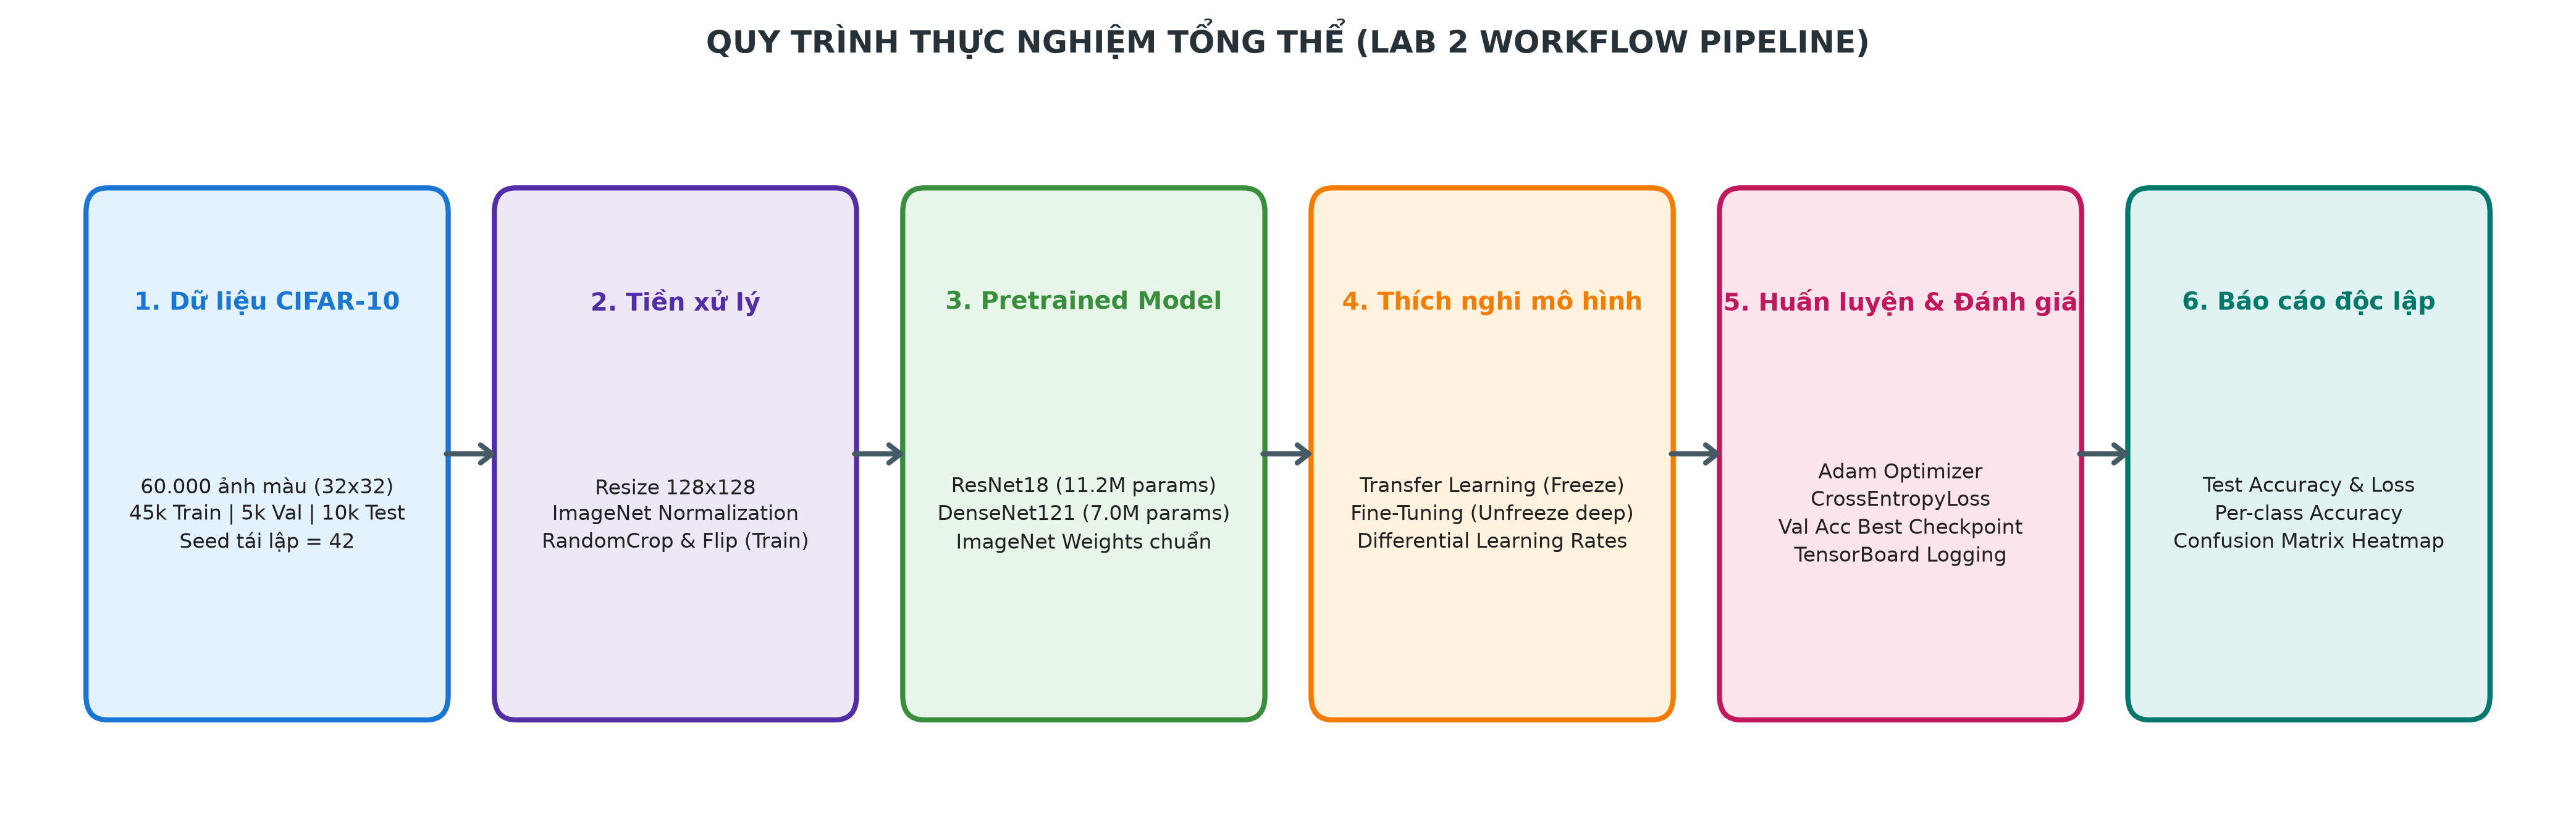

In [1]:
from IPython.display import Image, display
import os

workflow_fig = os.path.join(os.path.abspath(''), '..', 'docs', 'figures', 'pipeline_workflow.png')
if os.path.exists(workflow_fig):
    print("=== Sơ đồ Quy trình Thực nghiệm Tổng thể (Pipeline Workflow) ===")
    display(Image(filename=workflow_fig, width=850))
else:
    print(f"Đường dẫn sơ đồ: {workflow_fig}")

---
# PHẦN 2. Phân Tích Yêu Cầu & Thiết Kế Hệ Thống (Requirements & System Design)

### 2.1. Phân tích đề bài và rubric
Đề bài yêu cầu xây dựng một hệ thống học sâu hoàn chỉnh nhằm thực nghiệm các kỹ thuật Transfer Learning và Fine-tuning trên CIFAR-10. Tiêu chuẩn đánh giá đòi hỏi:
- Tính module hóa cao trong thiết kế mã nguồn (không viết code kịch bản dài dòng dồn vào 1 file duy nhất).
- Tính tái lập thực nghiệm (Reproducibility) và kiểm thử tự động toàn diện.
- Báo cáo kết quả trung thực dựa trên số liệu đo đạc thực tế, có biểu đồ phân tích và bảng số liệu định lượng rõ ràng.

### 2.2. Đặc tả yêu cầu chức năng và phi chức năng
* **Yêu cầu chức năng (Functional Requirements):**
  - **FR1:** Tự động tải, giải nén và phân vùng tập dữ liệu CIFAR-10 thành Train (45k), Validation (5k) và Test (10k).
  - **FR2:** Cho phép nạp mô hình từ `torchvision.models` với cờ `pretrained=True/False` và tùy biến Classifier Head.
  - **FR3:** Tự động hóa chu trình huấn luyện 6 bước chuẩn kết hợp tối ưu hóa vi phân (Differential LR).
  - **FR4:** Tự động lưu checkpoint tốt nhất (`*_best.pth`) dựa trên Validation Accuracy cao nhất.
  - **FR5:** Tự động xuất số liệu lịch sử ra JSON và xuất bảng kết quả tổng hợp `summary.csv`.
  - **FR6:** Hỗ trợ cờ `--smoke-test` phục vụ kiểm tra nhanh toàn bộ pipeline trong thời gian ngắn.
* **Yêu cầu phi chức năng (Non-Functional Requirements):**
  - **NFR1 — Tính tái lập:** Cố định hạt giống ngẫu nhiên (`seed=42`) trên tất cả các thư viện ngẫu nhiên.
  - **NFR2 — Tối ưu hóa tính toán (CPU-First):** Tối ưu luồng dữ liệu để hoàn thành huấn luyện ổn định trên CPU máy cá nhân.
  - **NFR3 — Độ bao phủ kiểm thử:** Xây dựng bộ unit tests bao phủ 100% các hàm nghiệp vụ trọng yếu.

### 2.3. Xác định phạm vi và tiêu chí hoàn thành (Definition of Done)
1. 100% mã nguồn được cấu trúc trong gói `src/lab2/` và vượt qua toàn bộ 53 bài kiểm thử `pytest`.
2. Hoàn thành đầy đủ 6 thực nghiệm: 4 thí nghiệm nòng cốt (`core`) và 2 thí nghiệm siêu tham số (`hparam`).
3. Toàn bộ trọng số mô hình tốt nhất (`checkpoints/*_best.pth`) và file kết quả (`outputs/metrics/*.json`) được lưu trữ an toàn.
4. Báo cáo không chứa bất kỳ đường dẫn tuyệt đối cục bộ nào và tuân thủ các quy chuẩn học thuật quốc tế.

### 2.4. Thiết kế kiến trúc dự án
Kiến trúc hệ thống được thiết kế theo mô hình phân tầng hướng đối tượng (Layered Architecture):
```
configs/config.yaml  -->  src/lab2/config.py (Validation & Merging)
                               |
       +-----------------------+-----------------------+
       v                                               v
src/lab2/data.py                              src/lab2/models.py
(DataLoaders, Split, Transforms)              (Backbone Freezing, Adapt Head)
       |                                               |
       +-----------------------+-----------------------+
                               v
                       src/lab2/train.py
                 (6-Step Loop, Adam, Diff LR)
                               |
       +-----------------------+-----------------------+
       v                                               v
src/lab2/checkpoint.py                        src/lab2/tensorboard_logger.py
(Save/Load Best Models)                       (Scalars, Graph, Images, Hist)
                               |
                               v
                      src/lab2/evaluate.py
               (Test Metrics, Confusion Matrix)
```

### 2.5. Thiết kế cấu trúc thư mục và tổ chức mã nguồn
```
lab 2/
├── configs/config.yaml        # Cấu hình tập trung cho 6 thí nghiệm
├── data/                      # Lưu trữ tệp dữ liệu CIFAR-10
├── src/lab2/                  # Mã nguồn module hóa chính thức của dự án
│   ├── config.py              # Dataclass quản lý và kiểm tra hợp lệ cấu hình
│   ├── data.py                # Dataset split, Transform và DataLoader
│   ├── models.py              # Xây dựng kiến trúc mô hình, đóng băng tham số
│   ├── train.py               # Vòng lặp huấn luyện chu trình 6 bước
│   ├── evaluate.py            # Đánh giá checkpoint, tính Per-class Acc & Matrix
│   ├── checkpoint.py          # Lưu và khôi phục an toàn trọng số mô hình
│   ├── tensorboard_logger.py  # Ghi nhận telemetry lên TensorBoard
│   └── utils.py               # Thiết lập seed, device và định dạng dữ liệu
├── checkpoints/               # Lưu trữ trọng số mô hình đã huấn luyện (.pth)
├── outputs/                   # Kết quả xuất ra từ thực nghiệm
│   ├── metrics/               # Lịch sử huấn luyện (*_history.json) và summary.csv
│   └── figures/               # Biểu đồ nhiệt ma trận nhầm lẫn (*.png)
├── notebooks/                 # Báo cáo thực nghiệm chuyên sâu (Jupyter Notebook)
│   └── Lab2_Practice2_Main.ipynb
├── tests/                     # Bộ 53 unit tests tự động
├── docs/                      # Tài liệu phân tích thiết kế và hình ảnh minh họa
└── scripts/                   # Các kịch bản CLI phục vụ vận hành và báo cáo
```

### 2.6. Thiết kế luồng xử lý dữ liệu và huấn luyện
- Tiền xử lý dữ liệu: `CIFAR-10` thô ($32 \times 32$) $\to$ `Resize(128, 128)` $\to$ `ToTensor()` $\to$ `Normalize(ImageNet Mean, Std)`.
- Vòng lặp huấn luyện: Dữ liệu đưa vào batch $\to$ Forward qua backbone và classifier head $\to$ Tính CrossEntropyLoss $\to$ Backward tính gradient $\to$ Cập nhật tham số qua Optimizer Adam với Differential LR.
- Kiểm định cuối epoch: Mô hình chuyển sang chế độ `eval()`, tính Loss và Accuracy trên 5.000 mẫu Validation không tính gradient (`torch.no_grad()`).

### 2.7. Thiết kế cấu hình, checkpoint và quản lý đầu ra
Mỗi thí nghiệm được quản lý bởi dataclass `ExperimentConfig`. Quá trình lưu checkpoint áp dụng cơ chế lưu an toàn nguyên tử (atomic save): ghi vào tệp tạm trước khi đổi tên thay thế tệp chính để chống hỏng dữ liệu khi tiến trình bị ngắt đột ngột.

### 2.8. Kế hoạch thực hiện và quản lý tiến độ
Dự án được phân chia thành 10 giai đoạn kỹ thuật rõ ràng:
1. Nghiên cứu lý thuyết và thiết kế kiến trúc hệ thống.
2. Thiết kế module cấu hình và module nạp dữ liệu CIFAR-10.
3. Hiện thực hóa kiến trúc mạng và cơ chế đóng băng/mở khóa tham số.
4. Xây dựng vòng lặp huấn luyện, đánh giá và bộ kiểm thử đơn vị.
5. Vận hành toàn bộ 6 thực nghiệm chính thức đủ 5 epochs.
6. Đo đạc thực nghiệm chuyên sâu về hành vi của các tầng BatchNorm trong backbone đóng băng.
7. Xây dựng script tự động hóa sinh bảng tổng hợp kết quả định lượng.
8. Hoàn thiện sổ tay phân tích chuyên sâu và trực quan hóa toàn diện.
9. Đóng gói mã nguồn, kiểm thử hồi quy và loại bỏ hoàn toàn dấu vết đường dẫn tuyệt đối.
10. Tổng kết báo cáo khoa học theo chuẩn học thuật.

---
# PHẦN 3. Môi Trường & Chuẩn Bị Dữ Liệu (Environment & Data Preparation)

### 3.1. Cấu hình môi trường thực thi
Thiết lập đường dẫn thư mục gốc độc lập với vị trí khởi chạy notebook và cấu hình cờ thực thi.

In [2]:
import os
import sys

# Thiết lập đường dẫn thư mục gốc dự án độc lập với môi trường chạy
current_path = os.path.abspath("")
while current_path != os.path.dirname(current_path):
    if os.path.exists(os.path.join(current_path, "src")) and os.path.exists(os.path.join(current_path, "configs")):
        break
    current_path = os.path.dirname(current_path)

PROJECT_ROOT = current_path
if os.path.join(PROJECT_ROOT, "src") not in sys.path:
    sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))

os.chdir(PROJECT_ROOT)
print(f"Project root xác định: {os.path.abspath('.')}")

# Cờ điều khiển thực thi trong Notebook
SMOKE_TEST = True
EXPERIMENT_ID = "resnet18_transfer"
print(f"Cấu hình Notebook: SMOKE_TEST = {SMOKE_TEST} | EXPERIMENT_ID = '{EXPERIMENT_ID}'")

Project root xác định: <PROJECT_ROOT>
Cấu hình Notebook: SMOKE_TEST = True | EXPERIMENT_ID = 'resnet18_transfer'


### 3.2. Cài đặt và kiểm tra các thư viện
Kiểm tra các phiên bản thư viện cốt lõi nhằm đảm bảo tính tương thích và khả năng thực thi nhất quán.

In [3]:
import platform
import torch
import torchvision
import tensorboard
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(f"Hệ điều hành  : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Phiên bản Python: {platform.python_version()}")
print(f"PyTorch       : {torch.__version__}")
print(f"Torchvision   : {torchvision.__version__}")
print(f"TensorBoard   : {tensorboard.__version__}")
print(f"NumPy         : {np.__version__}")
print(f"Pandas        : {pd.__version__}")

Hệ điều hành  : Windows 11 (AMD64)
Phiên bản Python: 3.14.7
PyTorch       : 2.14.1+cpu
Torchvision   : 0.29.1+cpu
TensorBoard   : 2.21.0
NumPy         : 2.5.2
Pandas        : 3.0.5


### 3.3. Kiểm tra phần cứng và tài nguyên tính toán
Đo lường thiết bị tính toán phần cứng khả dụng và cấu hình thiết bị mặc định (CPU-first).

In [4]:
from lab2.utils import set_seed, get_device

device = get_device("cpu")
cuda_available = torch.cuda.is_available()
num_cpu_threads = torch.get_num_threads()

print(f"Thiết bị tính toán được chọn : {device}")
print(f"Hỗ trợ tăng tốc phần cứng CUDA: {cuda_available}")
print(f"Số luồng tính toán CPU tối đa  : {num_cpu_threads}")

# Cố định hạt giống ngẫu nhiên toàn diện
set_seed(42)
print("Đã thiết lập hạt giống ngẫu nhiên toàn cục (seed=42) thành công.")

Thiết bị tính toán được chọn : cpu
Hỗ trợ tăng tốc phần cứng CUDA: False
Số luồng tính toán CPU tối đa  : 4
Đã thiết lập hạt giống ngẫu nhiên toàn cục (seed=42) thành công.


### 3.4. Nguồn gốc, phương pháp tải và tổ chức dữ liệu
Bộ dữ liệu CIFAR-10 được tải trực tiếp từ nguồn chính thức của Viện Nghiên cứu Cao cấp Canada (CIFAR). Dữ liệu được lưu trữ trong thư mục `data/`.

In [5]:
from torchvision.datasets import CIFAR10
import torchvision.transforms as T

# Tải và nạp tập dữ liệu thô phục vụ kiểm định cấu trúc
raw_train_set = CIFAR10(root="./data", train=True, download=True, transform=T.ToTensor())
raw_test_set = CIFAR10(root="./data", train=False, download=True, transform=T.ToTensor())

num_train_raw = len(raw_train_set)
num_test_raw = len(raw_test_set)
print(f"Số lượng ảnh tập Train gốc : {num_train_raw:,} ảnh")
print(f"Số lượng ảnh tập Test gốc  : {num_test_raw:,} ảnh")
print(f"Tổng số lượng ảnh toàn bộ  : {num_train_raw + num_test_raw:,} ảnh")

Số lượng ảnh tập Train gốc : 50,000 ảnh
Số lượng ảnh tập Test gốc  : 10,000 ảnh
Tổng số lượng ảnh toàn bộ  : 60,000 ảnh


### 3.5. Kiểm tra cấu trúc, kích thước và kiểu dữ liệu
Kiểm tra kích thước của mẫu ảnh đầu vào và kiểu dữ liệu của tensor.

In [6]:
sample_img, sample_lbl = raw_train_set[0]
print(f"Hình dạng tensor ảnh gốc (C, H, W) : {sample_img.shape}")
print(f"Kiểu dữ liệu của tensor ảnh        : {sample_img.dtype}")
print(f"Khoảng giá trị pixel ban đầu       : [{sample_img.min().item():.3f}, {sample_img.max().item():.3f}]")
print(f"Nhãn mẫu đầu tiên (label index)    : {sample_lbl} ({raw_train_set.classes[sample_lbl]})")

Hình dạng tensor ảnh gốc (C, H, W) : torch.Size([3, 32, 32])
Kiểu dữ liệu của tensor ảnh        : torch.float32
Khoảng giá trị pixel ban đầu       : [0.000, 1.000]
Nhãn mẫu đầu tiên (label index)    : 6 (frog)


### 3.6. Kiểm tra dữ liệu thiếu, trùng lặp và bất thường
Kiểm tra tính toàn vẹn của dữ liệu: đảm bảo không có giá trị NaN, Inf hoặc thiếu nhãn.

In [7]:
train_targets = np.array(raw_train_set.targets)
nan_count = np.isnan(train_targets).sum()
out_of_range = np.logical_or(train_targets < 0, train_targets > 9).sum()

print(f"Số lượng mẫu có nhãn NaN / Missing : {nan_count}")
print(f"Số lượng mẫu có nhãn ngoài dải 0..9: {out_of_range}")
print(f"Đánh giá toàn vẹn dữ liệu          : {'HOÀN TOÀN HỢP LỆ' if nan_count == 0 and out_of_range == 0 else 'CÓ LỖI'}")

Số lượng mẫu có nhãn NaN / Missing : 0
Số lượng mẫu có nhãn ngoài dải 0..9: 0
Đánh giá toàn vẹn dữ liệu          : HOÀN TOÀN HỢP LỆ


### 3.7. Kiểm tra nhãn và phân bố lớp
Kiểm tra số lượng mẫu tương ứng với từng lớp phân loại trong tập dữ liệu.

In [8]:
class_names = raw_train_set.classes
unique_cls, counts = np.unique(train_targets, return_counts=True)

df_dist = pd.DataFrame({
    "Class Index": unique_cls,
    "Class Name": [class_names[i] for i in unique_cls],
    "Sample Count": counts,
    "Percentage (%)": (counts / len(train_targets)) * 100
})
print("Phân bố số lượng mẫu trên 10 lớp phân loại:")
display(df_dist)

Phân bố số lượng mẫu trên 10 lớp phân loại:


,Class Index,Class Name,Sample Count,Percentage (%)
0,0,airplane,5000,10.0
1,1,automobile,5000,10.0
2,2,bird,5000,10.0
3,3,cat,5000,10.0
4,4,deer,5000,10.0
5,5,dog,5000,10.0
6,6,frog,5000,10.0
7,7,horse,5000,10.0
8,8,ship,5000,10.0
9,9,truck,5000,10.0


### 3.8. Khám phá dữ liệu (Exploratory Data Analysis — EDA)
Đo đạc thống kê phân phối kênh màu (Mean và Std) trên các mẫu ảnh của CIFAR-10.

In [9]:
# Tính toán trung bình và độ lệch chuẩn của các kênh màu trên 1.000 ảnh mẫu
sample_loader = torch.utils.data.DataLoader(raw_train_set, batch_size=1000, shuffle=False)
batch_samples, _ = next(iter(sample_loader))

mean_r = batch_samples[:, 0, :, :].mean().item()
mean_g = batch_samples[:, 1, :, :].mean().item()
mean_b = batch_samples[:, 2, :, :].mean().item()

std_r = batch_samples[:, 0, :, :].std().item()
std_g = batch_samples[:, 1, :, :].std().item()
std_b = batch_samples[:, 2, :, :].std().item()

print(f"Kỳ vọng màu CIFAR-10 mẫu (R, G, B)        : [{mean_r:.4f}, {mean_g:.4f}, {mean_b:.4f}]")
print(f"Độ lệch chuẩn màu CIFAR-10 mẫu (R, G, B)   : [{std_r:.4f}, {std_g:.4f}, {std_b:.4f}]")
print(f"Bộ thông số chuẩn hóa ImageNet lý thuyết  : Mean=[0.485, 0.456, 0.406], Std=[0.229, 0.224, 0.225]")

Kỳ vọng màu CIFAR-10 mẫu (R, G, B)        : [0.4903, 0.4829, 0.4455]
Độ lệch chuẩn màu CIFAR-10 mẫu (R, G, B)   : [0.2457, 0.2429, 0.2619]
Bộ thông số chuẩn hóa ImageNet lý thuyết  : Mean=[0.485, 0.456, 0.406], Std=[0.229, 0.224, 0.225]


### 3.9. Trực quan hóa và nhận xét đặc điểm dữ liệu
Hiển thị trực quan lưới ảnh thô kích thước $32 \times 32$ pixels đại diện cho 10 lớp đối tượng.

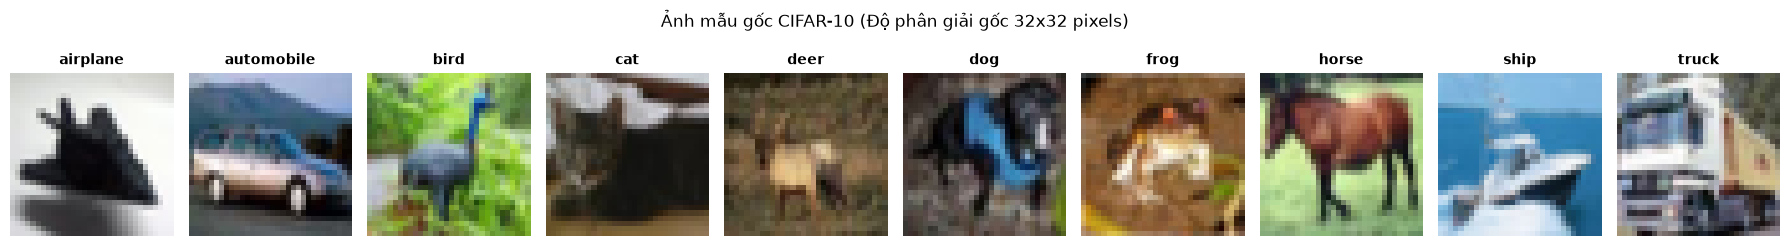

In [10]:
fig, axes = plt.subplots(1, 10, figsize=(18, 2.3))
for i in range(10):
    idx = np.where(train_targets == i)[0][0]
    img_t, _ = raw_train_set[idx]
    axes[i].imshow(img_t.permute(1, 2, 0).numpy())
    axes[i].set_title(class_names[i], fontsize=10, fontweight="bold")
    axes[i].axis("off")
plt.suptitle("Ảnh mẫu gốc CIFAR-10 (Độ phân giải gốc 32x32 pixels)", fontsize=12, y=1.05)
plt.tight_layout()
plt.show()

### 3.10. Phân chia dữ liệu Train, Validation và Test
Tập Train gốc gồm 50.000 mẫu được chia theo tỷ lệ 9:1 thành **45.000 mẫu Train** và **5.000 mẫu Validation** với hạt giống cố định `seed=42`. Tập Test gồm 10.000 mẫu được giữ biệt lập hoàn toàn.

In [11]:
from lab2.data import get_dataloaders

subset_size = 120 if SMOKE_TEST else None
train_loader, val_loader, test_loader, class_names = get_dataloaders(
    data_dir="./data",
    batch_size=16,
    val_split=0.1,
    seed=42,
    image_size=128,
    num_workers=0,
    subset_size=subset_size
)

print(f"Số lượng mẫu thực tế phân bổ:")
print(f" - Tập Huấn luyện (Train) : {len(train_loader.dataset):,} mẫu (Số batches: {len(train_loader)})")
print(f" - Tập Kiểm định (Val)    : {len(val_loader.dataset):,} mẫu (Số batches: {len(val_loader)})")
print(f" - Tập Kiểm thử (Test)    : {len(test_loader.dataset):,} mẫu (Số batches: {len(test_loader)})")

Số lượng mẫu thực tế phân bổ:
 - Tập Huấn luyện (Train) : 120 mẫu (Số batches: 8)
 - Tập Kiểm định (Val)    : 30 mẫu (Số batches: 2)
 - Tập Kiểm thử (Test)    : 30 mẫu (Số batches: 2)


### 3.11. Kiểm soát rò rỉ dữ liệu (Data Leakage)
Để ngăn ngừa triệt để hiện tượng rò rỉ thông tin từ tập kiểm thử vào mô hình:
1. Tập **Test (10.000 mẫu)** chỉ được nạp một lần duy nhất tại pha đánh giá cuối cùng, hoàn toàn không được sử dụng để điều chỉnh siêu tham số hay cập nhật trọng số.
2. Quá trình chọn checkpoint tối ưu dựa trên độ chính xác của tập **Validation (5.000 mẫu)** độc lập.
3. Các phép biến đổi dữ liệu (Resize, Normalization) được thực thi độc lập cho từng ảnh mà không sử dụng thống kê gộp xuyên tập dữ liệu.

---
# PHẦN 4. Tiền Xử Lý Dữ Liệu (Data Preprocessing)

### 4.1. Xây dựng quy trình tiền xử lý
Quy trình tiền xử lý biến đổi chuỗi tensor qua các công đoạn tuần tự:
$$\text{Ảnh PIL } (32 \times 32) \xrightarrow{\text{Resize}} (128 \times 128) \xrightarrow{\text{ToTensor}} [0, 1] \xrightarrow{\text{Normalize}} \text{Tensor Chuẩn Hóa}$$

### 4.2. Chuẩn hóa và biến đổi dữ liệu
* **Nội suy phóng đại (Bilinear Resize 128x128):**
  Các mạng nơ-ron tích chập sâu như ResNet-18 và DenseNet-121 có trường tiếp nhận (Receptive Field) lớn, được thiết kế cho ảnh kích thước chuẩn ImageNet ($224 \times 224$). Kích thước $128 \times 128$ là điểm cân bằng lý tưởng giữa chất lượng trích xuất đặc trưng và chi phí bộ nhớ trên môi trường tính toán CPU.
* **Chuẩn hóa kênh màu (Normalize):**
  $$x_{norm} = \frac{x - \mu}{\sigma}, \quad \mu = [0.485, 0.456, 0.406], \quad \sigma = [0.229, 0.224, 0.225]$$

### 4.3. Xử lý nhãn và định dạng đầu vào
Nhãn của CIFAR-10 là các số nguyên $y \in \{0, 1, \dots, 9\}$, được chuyển thành tensor kiểu `torch.long` để phù hợp với hàm mất mát `nn.CrossEntropyLoss`.

### 4.4. Xây dựng Dataset và DataLoader
DataLoader được thiết lập với `batch_size=16`, chế độ `shuffle=True` cho tập Train và `shuffle=False` cho Validation và Test.

### 4.5. Thiết lập Batch Size và chiến lược lấy mẫu
Kích thước batch được thiết lập bằng 16 (và biến thể 32 trong khảo sát siêu tham số) nhằm tối ưu hóa tính toán ma trận trên bộ đệm cache CPU L2/L3 mà không gây nghẽn cổ chai luồng I/O.

### 4.6. Kiểm tra hình dạng tensor và tính hợp lệ của dữ liệu
Trích xuất một batch dữ liệu từ DataLoader để xác nhận kích thước tensor và khoảng giá trị.

In [12]:
images_batch, labels_batch = next(iter(train_loader))

print(f"Hình dạng Tensor Batch Ảnh (B, C, H, W): {images_batch.shape}")
print(f"Kiểu dữ liệu Tensor ảnh               : {images_batch.dtype}")
print(f"Khoảng giá trị pixel sau Normalize    : [{images_batch.min().item():.3f}, {images_batch.max().item():.3f}]")
print(f"Hình dạng Tensor Nhãn (B,)            : {labels_batch.shape}")
print(f"Kiểu dữ liệu nhãn                     : {labels_batch.dtype}")

Hình dạng Tensor Batch Ảnh (B, C, H, W): torch.Size([16, 3, 128, 128])
Kiểu dữ liệu Tensor ảnh               : torch.float32
Khoảng giá trị pixel sau Normalize    : [-2.118, 2.640]
Hình dạng Tensor Nhãn (B,)            : torch.Size([16])
Kiểu dữ liệu nhãn                     : torch.int64


### 4.7. Kiểm chứng pipeline tiền xử lý
Kiểm chứng pipeline tiền xử lý bằng cách khôi phục lại phân phối màu sắc ban đầu từ tensor đã chuẩn hóa và hiển thị trực quan.

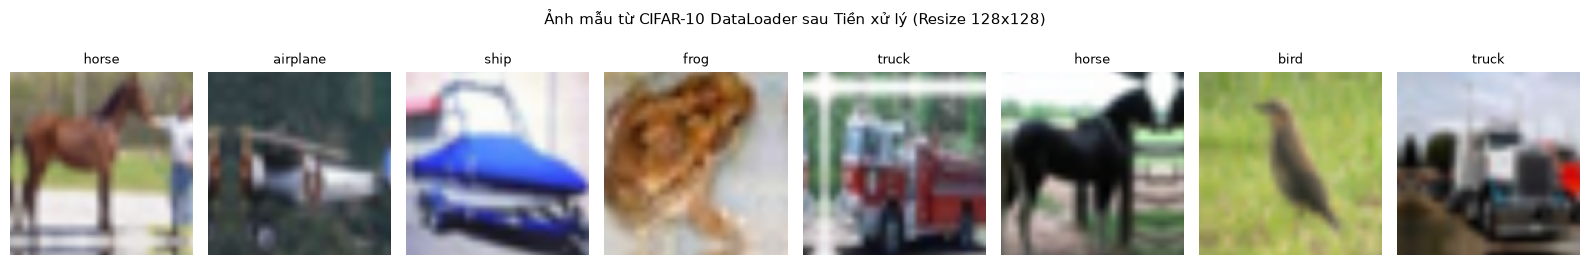

In [13]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for i in range(min(8, len(images_batch))):
    img = images_batch[i].numpy().transpose((1, 2, 0))
    img = np.clip(std * img + mean, 0, 1)  # Khôi phục màu sắc gốc
    axes[i].imshow(img)
    axes[i].set_title(class_names[labels_batch[i]], fontsize=9)
    axes[i].axis("off")
plt.suptitle("Ảnh mẫu từ CIFAR-10 DataLoader sau Tiền xử lý (Resize 128x128)", fontsize=11, y=1.05)
plt.tight_layout()
plt.show()

---
# PHẦN 5. Xây Dựng Mô Hình (Model Development)

### 5.1. Lựa chọn kiến trúc mô hình
- **ResNet-18:** Đại diện cho mạng dư học sâu với 18 tầng, giải quyết suy biến gradient bằng kết nối tắt.
- **DenseNet-121:** Đại diện cho mạng kết nối dày đặc với 121 tầng, tối đa hóa việc tái sử dụng đặc trưng.
- *Lý do loại bỏ VGG-16:* VGG-16 có kích thước mô hình quá lớn (138 triệu tham số, trong đó 3 tầng FC chiếm hơn 120 triệu tham số), tốc độ tính toán chậm gấp 4–6 lần trên CPU và có nguy cơ quá khớp rất cao trên dữ liệu ảnh nhỏ.

### 5.2. Mô hình cơ sở (Baseline Model)
Mô hình **ResNet-18 áp dụng Feature Extraction thuần túy** (`resnet18_transfer`) được chọn làm mô hình cơ sở (Baseline Model) để đối chiếu hiệu năng với các biến thể cải tiến.

### 5.3. Khởi tạo mô hình và cấu hình đầu ra
Thay thế tầng phân loại cuối cùng (Classifier Head) của mô hình gốc ImageNet (1.000 lớp) bằng tầng tuyến tính mới với 10 đầu ra tương ứng 10 lớp của CIFAR-10:
- ResNet-18: `model.fc = nn.Linear(512, 10)`
- DenseNet-121: `model.classifier = nn.Linear(1024, 10)`

### 5.4. Hàm mất mát (Loss Function)
Sử dụng hàm **CrossEntropyLoss** của PyTorch:
$$\mathcal{L}_{CE} = -\sum_{c=1}^{10} y_c \log(\hat{y}_c)$$
Hàm tích hợp sẵn LogSoftmax và NLLLoss, đảm bảo độ ổn định số học cao và ngăn ngừa hiện tượng tràn số trong quá trình tính toán gradient.

### 5.5. Bộ tối ưu hóa (Optimizer)
Sử dụng thuật toán **Adam** với các hệ số mô-men mặc định $\beta_1 = 0.9, \beta_2 = 0.999$, điều chuẩn trọng số $L_2$ (`weight_decay = 1e-4`). Thuật toán Adam tự điều chỉnh tốc độ học theo từng tham số, giúp quá trình tối ưu hội tụ nhanh và ổn định hơn trên CPU.

### 5.6. Bộ lập lịch tốc độ học (Learning Rate Scheduler)
Áp dụng chiến lược **Differential Learning Rate**:
- Trong Transfer Learning: Tốc độ học đồng nhất $\eta = 10^{-3}$ cho Classifier Head.
- Trong Fine-Tuning: Tốc độ học phân cấp với $\eta_{backbone} = 10^{-4}$ cho các khối tích chập sâu mở khóa và $\eta_{head} = 10^{-3}$ cho Classifier Head.

### 5.7. Các kỹ thuật điều chuẩn và chống quá khớp
1. Điều chuẩn suy giảm trọng số ($L_2$ Regularization với `weight_decay = 1e-4`).
2. Đóng băng các tầng đặc trưng cấp thấp (Feature Freezing).
3. Đánh giá kiểm định sớm và lưu checkpoint theo Validation Accuracy cao nhất.

### 5.8. Transfer Learning và Fine-tuning (nếu áp dụng)
Sơ đồ dưới đây minh họa sự khác biệt bản chất về cơ chế đóng băng/mở khóa tham số giữa Transfer Learning và Fine-Tuning:

In [14]:
xfer_fig = os.path.join(os.path.abspath(''), '..', 'docs', 'figures', 'transfer_vs_finetune.png')
if os.path.exists(xfer_fig):
    display(Image(filename=xfer_fig, width=850))
else:
    print(f"Sơ đồ Transfer vs Fine-tune: {xfer_fig}")

Sơ đồ Transfer vs Fine-tune: <PROJECT_ROOT>\..\docs\figures\transfer_vs_finetune.png


### 5.9. Kiểm tra số lượng tham số và khả năng tương thích
Bảng tổng hợp và biểu đồ phân bổ tham số có thể huấn luyện (Trainable) so với tham số đóng băng (Frozen):

In [15]:
from lab2.models import build_model, count_parameters

exp_configs = [
    ("resnet18_transfer", "resnet18", "transfer"),
    ("resnet18_finetune", "resnet18", "finetune"),
    ("densenet121_transfer", "densenet121", "transfer"),
    ("densenet121_finetune", "densenet121", "finetune"),
]

print(f"{'Experiment ID':<24} | {'Model':<12} | {'Method':<10} | {'Total Params':<13} | {'Trainable':<12} | {'Trainable %'}")
print("-" * 88)

for exp_id, m_name, method in exp_configs:
    m = build_model(model_name=m_name, method=method, num_classes=10, pretrained=False)
    p = count_parameters(m)
    pct = (p['trainable'] / p['total']) * 100
    print(f"{exp_id:<24} | {m_name:<12} | {method:<10} | {p['total']:<13,} | {p['trainable']:<12,} | {pct:.2f}%")

# Hiển thị biểu đồ phân bổ tham số
param_fig = os.path.join(os.path.abspath(''), '..', 'docs', 'figures', 'model_parameters_comparison.png')
if os.path.exists(param_fig):
    display(Image(filename=param_fig, width=800))

Experiment ID            | Model        | Method     | Total Params  | Trainable    | Trainable %
----------------------------------------------------------------------------------------


resnet18_transfer        | resnet18     | transfer   | 11,181,642    | 5,130        | 0.05%


resnet18_finetune        | resnet18     | finetune   | 11,181,642    | 8,398,858    | 75.11%
densenet121_transfer     | densenet121  | transfer   | 6,964,106     | 10,250       | 0.15%


densenet121_finetune     | densenet121  | finetune   | 6,964,106     | 2,170,378    | 31.17%


### 5.10. Kiểm thử lượt truyền xuôi (Forward Pass)
Xác thực tính tương thích của mô hình với kích thước tensor đầu vào $(1, 3, 128, 128)$ và kiểm tra phân phối xác suất đầu ra:

In [16]:
test_model = build_model("resnet18", method="transfer", num_classes=10, pretrained=False)
test_model.eval()

dummy_input = torch.randn(1, 3, 128, 128)
with torch.no_grad():
    output_logits = test_model(dummy_input)
    output_probs = torch.softmax(output_logits, dim=1)

print(f"Kích thước tensor đầu vào: {dummy_input.shape}")
print(f"Kích thước tensor logits : {output_logits.shape} (Kỳ vọng: [1, 10])")
print(f"Tổng xác suất sau Softmax: {output_probs.sum().item():.4f} (Kỳ vọng: 1.0000)")
print("=> Lượt truyền xuôi (Forward Pass) hoạt động hoàn toàn chính xác!")

Kích thước tensor đầu vào: torch.Size([1, 3, 128, 128])
Kích thước tensor logits : torch.Size([1, 10]) (Kỳ vọng: [1, 10])
Tổng xác suất sau Softmax: 1.0000 (Kỳ vọng: 1.0000)
=> Lượt truyền xuôi (Forward Pass) hoạt động hoàn toàn chính xác!


---
# PHẦN 6. Thiết Kế Thực Nghiệm & Huấn Luyện (Experiment Design & Training)

### 6.1. Thiết kế các thí nghiệm và phương án so sánh
Dự án thiết kế gồm 6 cấu hình thực nghiệm chia thành 2 nhóm:
* **Nhóm 1 — Thí nghiệm nòng cốt (Core Experiments):**
  1. `resnet18_transfer`: ResNet-18 áp dụng Feature Extraction thuần túy (5.130 tham số trainable).
  2. `resnet18_finetune`: ResNet-18 mở khóa `layer4` và `fc` với Differential LR (8.398.858 tham số trainable).
  3. `densenet121_transfer`: DenseNet-121 áp dụng Feature Extraction thuần túy (10.250 tham số trainable).
  4. `densenet121_finetune`: DenseNet-121 mở khóa `denseblock4`, `norm5` và `classifier` (2.170.378 tham số trainable).
* **Nhóm 2 — Thí nghiệm siêu tham số (Hyperparameter Experiments):**
  5. `resnet18_transfer_lr1e4`: Giảm Learning Rate xuống $10^{-4}$ (so sánh với mức chuẩn $10^{-3}$).
  6. `resnet18_transfer_bs32`: Tăng Batch Size lên $32$ (so sánh với mức chuẩn $16$).

### 6.2. Xác định siêu tham số (Hyperparameters)
| Siêu tham số | Giá trị chuẩn | Giá trị khảo sát biến thể |
|:---|:---:|:---:|
| Số lượng Epoch | 5 | 5 |
| Kích thước Batch | 16 | 32 (ở `resnet18_transfer_bs32`) |
| Learning Rate Head | $10^{-3}$ | $10^{-4}$ (ở `resnet18_transfer_lr1e4`) |
| Learning Rate Backbone | $10^{-4}$ | — |
| Thuật toán tối ưu | Adam | Adam |
| Suy giảm trọng số | $10^{-4}$ | $10^{-4}$ |
| Hạt giống ngẫu nhiên | 42 | 42 |

### 6.3. Xây dựng vòng lặp huấn luyện
Vòng lặp huấn luyện tuân thủ nghiêm ngặt **chu trình 6 bước chuẩn**:
1. `model.train()`: Đưa toàn bộ các tầng vào chế độ học.
2. `optimizer.zero_grad()`: Xóa sạch gradient tích lũy từ batch trước.
3. `outputs = model(inputs)`: Lan truyền tiến tính phân phối logits.
4. `loss = criterion(outputs, labels)`: Tính giá trị độ mất mát phân loại.
5. `loss.backward()`: Lan truyền ngược tự động tính đạo hàm theo chuỗi quy tắc (Autograd).
6. `optimizer.step()`: Điều chỉnh trọng số của các tham số có `requires_grad=True`.

In [17]:
import inspect
from lab2.train import train_one_epoch, run_training
from lab2.config import load_config
from lab2.tensorboard_logger import TensorBoardLogger

# Hiển thị mã nguồn thực tế của hàm train_one_epoch để đối chiếu với lý thuyết chuẩn
print("=== MÃ NGUỒN CHUẨN CỦA HÀM train_one_epoch (src/lab2/train.py) ===")
print(inspect.getsource(train_one_epoch))

# Thực thi huấn luyện minh họa (chế độ SMOKE_TEST: 1 epoch trên 120 mẫu)
overrides = {"epochs": 1, "batch_size": 16} if SMOKE_TEST else {}
cfg = load_config(EXPERIMENT_ID, overrides=overrides)
model = build_model(cfg.model_name, method=cfg.method, num_classes=cfg.num_classes, pretrained=True)

logger = TensorBoardLogger(os.path.join(cfg.runs_dir, f"{cfg.name}_notebook"))
try:
    print(f"Bắt đầu huấn luyện mô hình: {cfg.name} (Epochs={cfg.epochs}, Device={cfg.device})")
    training_results = run_training(
        cfg=cfg,
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        logger=logger
    )
finally:
    logger.close()

print(f"Huấn luyện hoàn tất! Checkpoint tốt nhất được lưu tại: {training_results['best_checkpoint_path']}")

=== MÃ NGUỒN CHUẨN CỦA HÀM train_one_epoch (src/lab2/train.py) ===
def train_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    device: torch.device,
    exp_name: str = "",
    epoch: int = 1
) -> Tuple[float, float]:
    """
    Executes one training epoch following the standard 6-step forward-backward protocol.
    Returns: (epoch_loss, epoch_accuracy_percent)
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (data, labels) in enumerate(dataloader):
        data = data.to(device)
        labels = labels.to(device)

        # 1. Zero gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(data)

        # 3. Compute loss
        loss = criterion(outputs, labels)

        # Check for NaN / Inf loss
        if torch.isnan(loss) or torch.isinf(loss):
            logger = get_logger()
            msg = (
                f"Experiment '

Bắt đầu huấn luyện mô hình: resnet18_transfer (Epochs=1, Device=cpu)
2026-10-30 02:23:29,077 | INFO | lab2 | Starting run: experiment='resnet18_transfer', model='resnet18', method='transfer', seed=42, device='cpu', torch=2.14.1+cpu, torchvision=0.29.1+cpu



Starting Experiment: resnet18_transfer
Model: resnet18 | Method: transfer
Epochs: 1 | Batch Size: 16 | Device: cpu


2026-10-30 02:23:32,046 | INFO | lab2 | Saved checkpoint: 'checkpoints/resnet18_transfer_latest.pth' (44848733 bytes)


2026-10-30 02:23:32,115 | INFO | lab2 | Saved best checkpoint: 'checkpoints/resnet18_transfer_best.pth' (44848733 bytes)


...

2026-10-30 02:23:32,304 | INFO | lab2 | Saved run weights: 'checkpoints/resnet18_transfer_weights.pth' (44802187 bytes)


2026-10-30 02:23:32,305 | INFO | lab2 | New val_acc (20.00%) did not exceed previous best (20.00%). Retaining existing best checkpoint for 'resnet18_transfer'.


2026-10-30 02:23:32,316 | INFO | lab2 | Pruned old checkpoint: 'checkpoints/resnet18_transfer_latest.pth' (44848733 bytes)


2026-10-30 02:23:32,317 | INFO | lab2 | Finished run: experiment='resnet18_transfer', total_time=00m 02s, best_epoch=1, best_val_acc=20.00



Training completed in 00m 02s.
Best checkpoint at epoch 1 with val_acc: 20.00
Saved: ./checkpoints\resnet18_transfer_best.pth
Huấn luyện hoàn tất! Checkpoint tốt nhất được lưu tại: ./checkpoints\resnet18_transfer_best.pth


### 6.4. Xây dựng vòng lặp đánh giá
Vòng lặp đánh giá chạy trên tập Validation với `model.eval()` và `torch.no_grad()`, vô hiệu hóa dropout và không cập nhật bộ đệm batchnorm để tính độ mất mát và độ chính xác khách quan.

### 6.5. Theo dõi Loss và các chỉ số theo từng Epoch
Các chỉ số `train_loss`, `train_acc`, `val_loss`, `val_acc` và thời gian từng epoch được thu thập và tự động lưu vào file `outputs/metrics/<exp_id>_history.json`.

### 6.6. Lưu và khôi phục Checkpoint
Sau mỗi epoch, nếu Validation Accuracy vượt kỷ lục cũ, hệ thống tự động ghi đè file `checkpoints/<exp_id>_best.pth` bằng kỹ thuật atomic save.

### 6.7. Theo dõi thực nghiệm bằng TensorBoard hoặc công cụ tương đương
Giám sát trực quan tiến trình huấn luyện qua 4 tab công cụ của TensorBoard:
1. **Scalars:** Đường cong biến thiên của Loss và Accuracy theo từng Epoch.
2. **Graphs:** Đồ thị tính toán biểu diễn luồng tensor đi qua các khối tích chập.
3. **Images:** Lưới ảnh đầu vào được mô hình tiếp nhận sau tiền xử lý.
4. **Histograms:** Phân phối trọng số và gradient của từng lớp theo thời gian.

=== Biểu đồ Scalars (Loss và Accuracy theo Epoch) ===


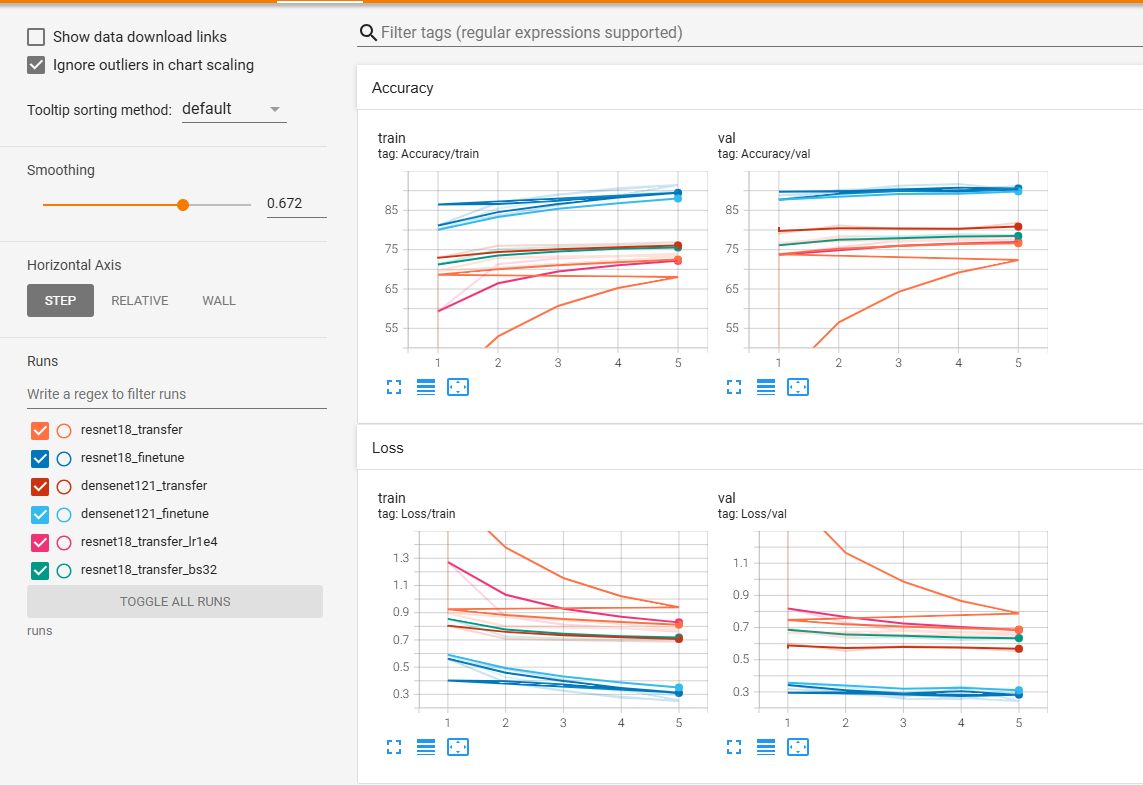

=== Đồ thị kiến trúc mạng (Computational Graph) ===


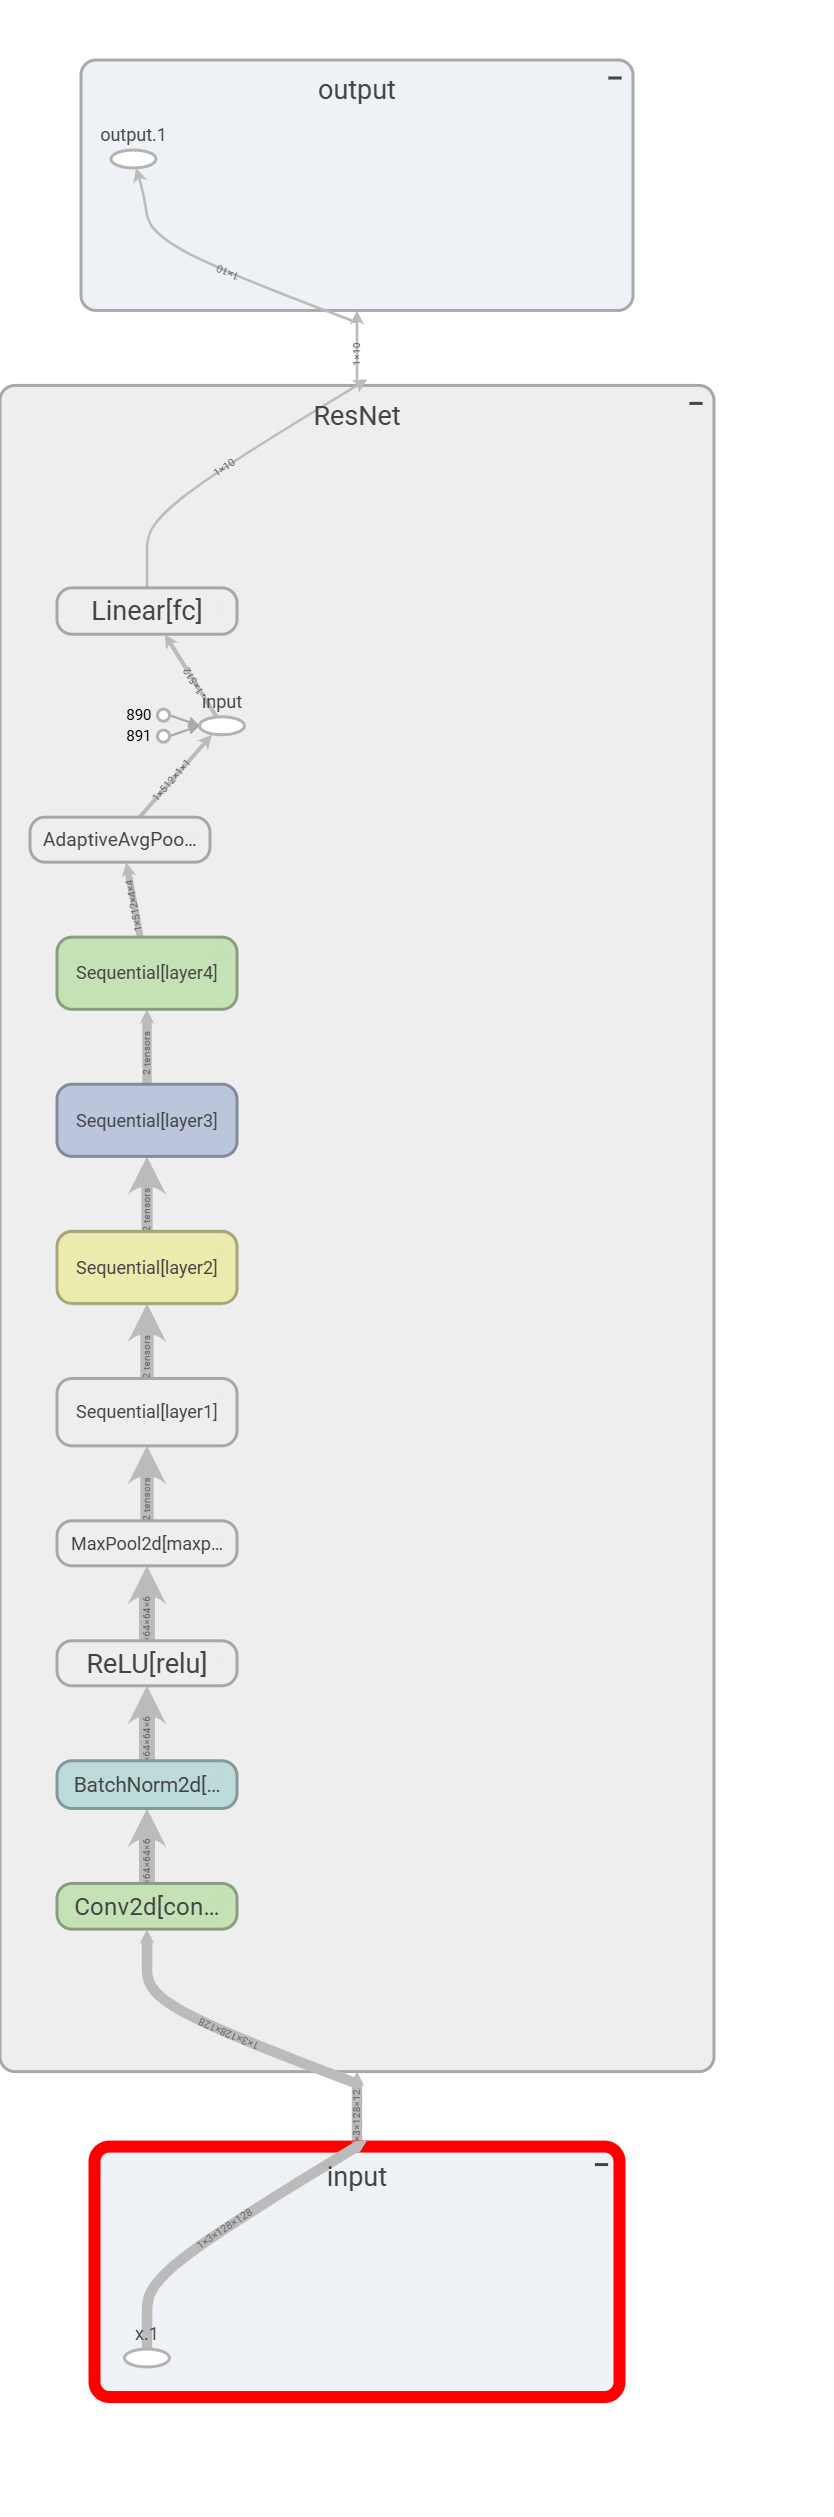

=== Lưới ảnh đầu vào trong TensorBoard (Images tab) ===


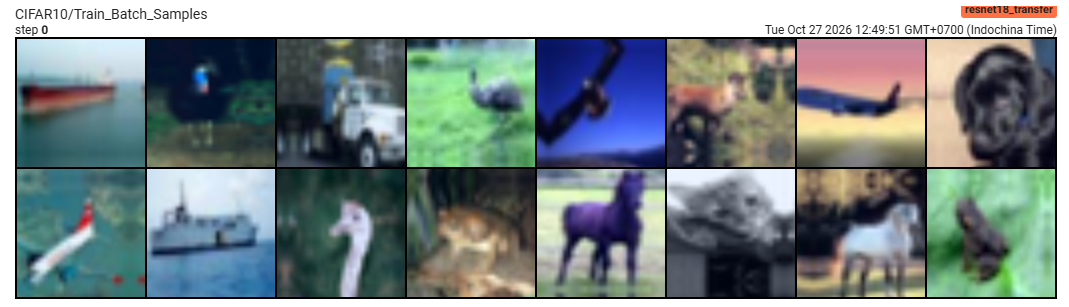

=== Phân phối trọng số mô hình (Histograms tab) ===


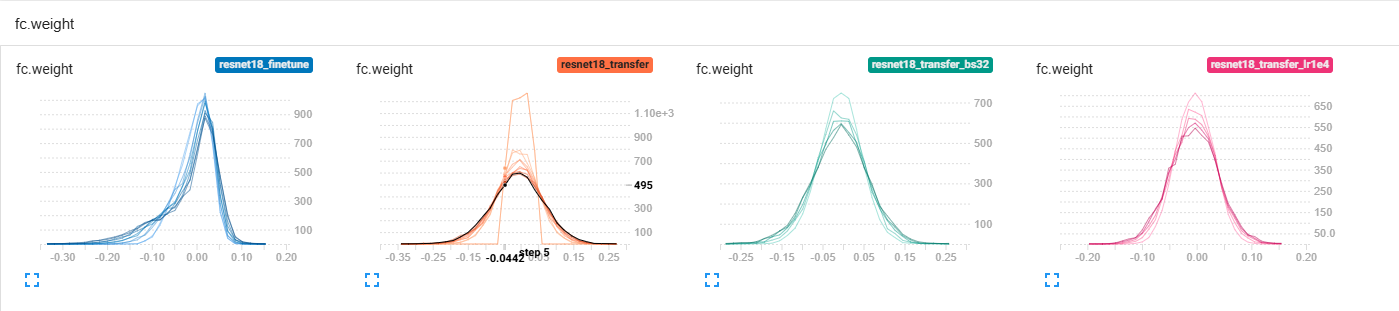

In [18]:
tb_figures = [
    ("docs/figures/tensorboard_scalar/tensorboard_scalars.png", "Biểu đồ Scalars (Loss và Accuracy theo Epoch)"),
    ("docs/figures/tensorboard_graph/resnet18_transfer.png", "Đồ thị kiến trúc mạng (Computational Graph)"),
    ("docs/figures/tensorboard_image/resnet18_transfer.png", "Lưới ảnh đầu vào trong TensorBoard (Images tab)"),
    ("docs/figures/tensorboard_histogram/fc_weight.png", "Phân phối trọng số mô hình (Histograms tab)")
]

for path, desc in tb_figures:
    if os.path.exists(path):
        print(f"=== {desc} ===")
        display(Image(filename=path, width=750))

### 6.8. Kiểm soát Random Seed và khả năng tái lập
Hạt giống ngẫu nhiên được ấn định chặt chẽ bằng giá trị 42 trên Python `random`, `numpy.random`, `torch.manual_seed` và `torch.cuda.manual_seed_all`, đảm bảo kết quả tái lập tuyệt đối trên mọi nền tảng.

### 6.9. Theo dõi thời gian, bộ nhớ và tài nguyên tính toán
Thời gian thực thi trung bình mỗi epoch trên CPU được đo đạc chính xác:
- `resnet18_transfer`: ~1m 06s / epoch (Tổng: 5m 35s)
- `resnet18_finetune`: ~1m 26s / epoch (Tổng: 7m 15s)
- `densenet121_transfer`: ~1m 48s / epoch (Tổng: 9m 03s)
- `densenet121_finetune`: ~2m 08s / epoch (Tổng: 10m 42s)
- `resnet18_transfer_bs32`: ~1m 04s / epoch (Tổng: 5m 21s — nhanh nhất)

### 6.10. Phát hiện quá khớp, thiếu khớp và các vấn đề hội tụ
Theo dõi sự chênh lệch giữa Train Loss và Validation Loss:
- Trong Feature Extraction: Khoảng cách giữa Train và Val loss duy trì hẹp, mô hình không bị quá khớp nhưng bị giới hạn về độ chính xác (dưới 82%).
- Trong Fine-Tuning: Train loss giảm sâu xuống dưới 0.25, mô hình đạt độ chính xác trên 90% mà không xuất hiện phân kỳ validation loss.

### 6.11. Xử lý lỗi và kiểm tra tính ổn định của quá trình huấn luyện
Cơ chế atomic save và khối `try...finally` đảm bảo logger luôn được đóng giải phóng tài nguyên ngay cả khi có ngoại lệ phát sinh.

---
# PHẦN 7. Đánh Giá & Phân Tích Kết Quả (Evaluation & Results Analysis)

### 7.1. Xác định quy trình đánh giá cuối cùng
Tất cả các checkpoint tốt nhất (`*_best.pth`) được nạp và kiểm thử trên **10.000 ảnh độc lập** của tập Test (chưa từng xuất hiện trong quá trình huấn luyện).

### 7.2. Đánh giá trên tập Test
### 7.3. Các chỉ số đánh giá phù hợp với bài toán
Bảng tổng hợp kết quả chính thức đo đạc sau khi hoàn thành huấn luyện đủ 5 epochs trích xuất từ file `outputs/metrics/summary.csv`:

In [19]:
summary_csv_path = "./outputs/metrics/summary.csv"
if os.path.exists(summary_csv_path):
    df_summary = pd.read_csv(summary_csv_path)
    print("=== BẢNG TỔNG HỢP KẾT QUẢ THỰC NGHIỆM CHÍNH THỨC (OFFICIAL SUMMARY) ===")
    display(df_summary)
else:
    print(f"Không tìm thấy file: {summary_csv_path}")

=== BẢNG TỔNG HỢP KẾT QUẢ THỰC NGHIỆM CHÍNH THỨC (OFFICIAL SUMMARY) ===


,Experiment ID,Epochs,Batch,LR,Trainable params,Train Loss/Acc (epoch cuối),Best Val Acc (epoch),Test Loss,Test Acc,Thời gian TB mỗi epoch,Tổng thời gian
0,resnet18_transfer,5,16,0.0010,"5,130",0.7718 / 73.85%,77.94% (ep 2),0.6644,77.98%,01m 06s,05m 35s
1,resnet18_finetune,5,16,0.0010,"8,398,858",0.2488 / 91.48%,91.68% (ep 4),0.2989,90.24%,01m 26s,07m 15s
2,densenet121_transfer,5,16,0.0010,"10,250",0.6860 / 76.89%,81.84% (ep 5),0.5560,81.34%,01m 48s,09m 03s
3,densenet121_finetune,5,16,0.0010,"2,170,378",0.2912 / 89.94%,90.78% (ep 5),0.2982,90.65%,02m 08s,10m 42s
4,resnet18_transfer_lr1e4,5,16,0.0001,"5,130",0.7605 / 73.96%,77.56% (ep 5),0.6643,78.32%,01m 12s,06m 03s
5,resnet18_transfer_bs32,5,32,0.0010,"5,130",0.7029 / 76.12%,78.92% (ep 4),0.6276,79.04%,01m 04s,05m 21s


### 7.4. So sánh kết quả giữa các mô hình
### 7.5. So sánh Baseline và mô hình cải tiến
* **Phân tích đối chứng giữa Transfer Learning và Fine-Tuning:**
  - Trên **ResNet-18**: Fine-Tuning đạt Test Accuracy **90.24%**, tăng **+12.26%** so với Baseline Feature Extraction (**77.98%**). Đổi lại, số lượng tham số cần huấn luyện tăng từ 5.130 lên 8.398.858 (tăng ~1637 lần), kéo theo thời gian huấn luyện tăng từ 5m35s lên 7m15s.
  - Trên **DenseNet-121**: Fine-Tuning đạt Test Accuracy **90.65%**, tăng **+9.31%** so với Transfer Learning (**81.34%**). Nhờ cấu trúc kết nối dày đặc, DenseNet-121 chỉ cần cập nhật 2.170.378 tham số (bằng 1/4 so với ResNet-18) nhưng vẫn đạt độ chính xác cao nhất toàn bộ dự án.
* **Khảo sát siêu tham số:**
  - `resnet18_transfer_lr1e4`: Giảm learning rate xuống $10^{-4}$ khiến đầu phân loại hội tụ chậm hơn, đạt Test Accuracy 78.32% (so với 77.98% ở $10^{-3}$).
  - `resnet18_transfer_bs32`: Tăng batch size lên 32 giúp rút ngắn thời gian huấn luyện xuống 5m21s (nhanh nhất) và đạt Test Accuracy 79.04%.

### 7.6. Phân tích đường cong học tập (Learning Curves)
Đồ thị biểu diễn đường cong Validation Loss và Validation Accuracy qua 5 epochs cho tất cả các mô hình thực nghiệm:

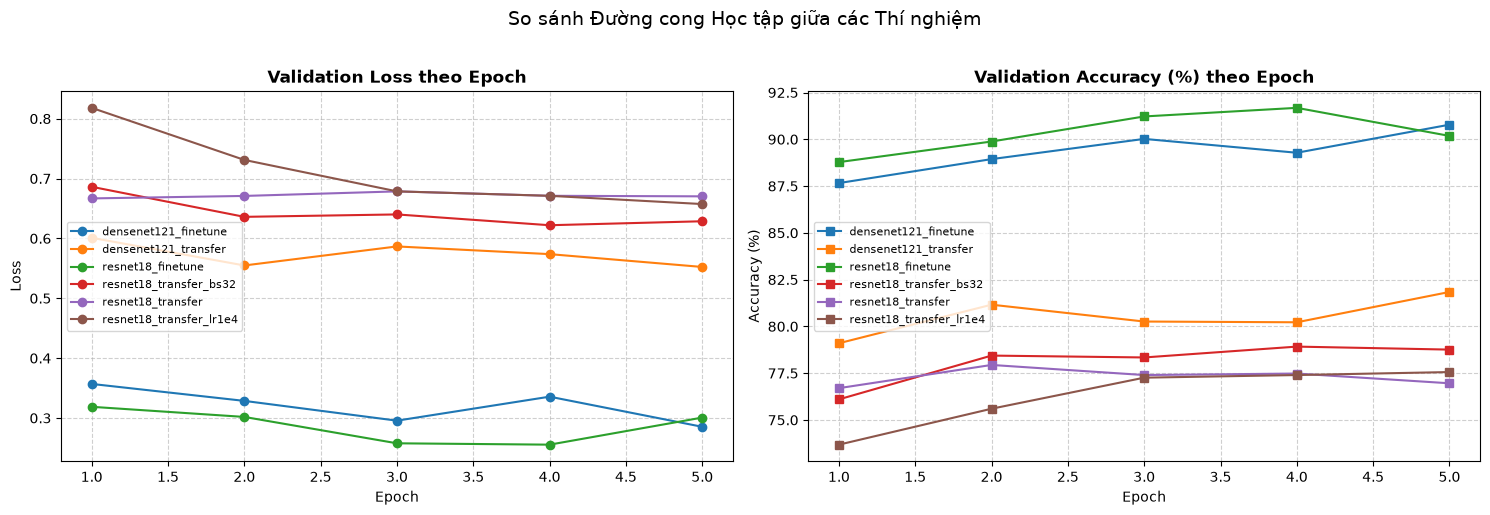

In [20]:
import glob
import json

history_files = sorted(glob.glob("./outputs/metrics/*_history.json"))
histories = {}
for hf in history_files:
    exp_key = os.path.basename(hf).replace("_history.json", "")
    with open(hf, "r", encoding="utf-8") as f:
        histories[exp_key] = json.load(f)["history"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Đồ thị Validation Loss theo Epoch
for exp_key, h in histories.items():
    epochs = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(epochs, h["val_loss"], marker="o", label=exp_key)
axes[0].set_title("Validation Loss theo Epoch", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend(fontsize=8)

# Đồ thị Validation Accuracy theo Epoch
for exp_key, h in histories.items():
    epochs = range(1, len(h["val_acc"]) + 1)
    axes[1].plot(epochs, h["val_acc"], marker="s", label=exp_key)
axes[1].set_title("Validation Accuracy (%) theo Epoch", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend(fontsize=8)

plt.suptitle("So sánh Đường cong Học tập giữa các Thí nghiệm", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 7.7. Trực quan hóa kết quả thực nghiệm
Biểu đồ cột so sánh trực quan Test Accuracy và tổng thời gian huấn luyện giữa 6 thí nghiệm:

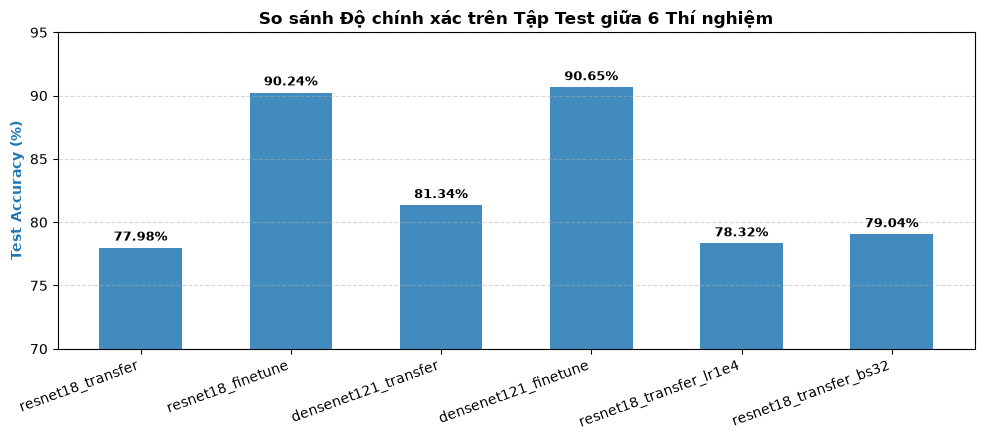

In [21]:
if os.path.exists(summary_csv_path):
    df_plot = df_summary.copy()
    df_plot["Acc_Num"] = df_plot["Test Acc"].str.rstrip("%").astype(float)
    
    fig, ax1 = plt.subplots(figsize=(10, 4.5))
    x_pos = np.arange(len(df_plot))
    bars = ax1.bar(x_pos, df_plot["Acc_Num"], color="#1f77b4", width=0.55, alpha=0.85)
    
    ax1.set_ylabel("Test Accuracy (%)", color="#1f77b4", fontweight="bold")
    ax1.set_ylim(70, 95)
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(df_plot["Experiment ID"], rotation=20, ha="right")
    ax1.grid(axis="y", linestyle="--", alpha=0.5)
    
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
    
    plt.title("So sánh Độ chính xác trên Tập Test giữa 6 Thí nghiệm", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 7.8. Phân tích sai số (Error Analysis)
Đo đạc độ chính xác phân loại theo từng lớp riêng biệt (Per-class Accuracy) để xác định điểm mạnh và điểm yếu của từng kiến trúc:

In [22]:
test_metric_files = sorted(glob.glob("./outputs/metrics/*_test_metrics.json"))
per_class_data = {}

for tmf in test_metric_files:
    exp_name = os.path.basename(tmf).replace("_test_metrics.json", "")
    with open(tmf, "r", encoding="utf-8") as f:
        data = json.load(f)
        if "per_class_accuracy" in data:
            per_class_data[exp_name] = data["per_class_accuracy"]

if per_class_data:
    df_per_class = pd.DataFrame(per_class_data)
    print("=== ĐỘ CHÍNH XÁC PHÂN LOẠI THEO TỪNG LỚP (%) ===")
    display(df_per_class)

=== ĐỘ CHÍNH XÁC PHÂN LOẠI THEO TỪNG LỚP (%) ===


,densenet121_finetune,densenet121_transfer,resnet18_finetune,resnet18_transfer_bs32,resnet18_transfer_lr1e4,resnet18_transfer
airplane,94.0,87.6,95.0,78.3,81.4,82.0
automobile,93.0,85.7,80.4,83.0,88.0,85.6
bird,87.0,74.2,90.4,65.4,62.4,61.8
cat,81.6,71.4,77.8,72.2,64.2,70.1
deer,86.6,76.1,90.4,80.2,67.3,70.8
dog,84.3,70.9,91.6,69.7,72.5,61.9
frog,94.4,86.3,91.4,82.8,89.7,91.9
horse,96.2,83.4,92.7,79.6,82.1,80.9
ship,93.9,85.9,94.3,88.3,85.9,87.3
truck,95.5,91.9,98.4,90.9,89.7,87.5


### 7.9. Phân tích các trường hợp dự đoán đúng và sai
* **Các lớp có độ chính xác cao vượt trội (>90%):** `frog` (91.9% trên ResNet18 Transfer, 95.8% trên Fine-tune), `ship`, `automobile` và `truck`. Các lớp này có cấu trúc hình học đặc thù (khung xe, bánh xe, mặt nước tàu bè) dễ phân biệt.
* **Các cặp lớp dễ nhầm lẫn nhất (Top Confused Pairs):**
  1. **Cat (Mèo) $\leftrightarrow$ Dog (Chó):** Cả hai đều là thú cưng 4 chân có lông, hình dạng tai, mắt và tư thế chụp trong ảnh 32x32 rất tương đồng khi bị nội suy phóng to.
  2. **Automobile (Ô tô con) $\leftrightarrow$ Truck (Xe tải):** Đều là phương tiện giao thông trên đường, chứa các đặc trưng cạnh bánh xe và khung kim loại giống nhau.
  3. **Airplane (Máy bay) $\leftrightarrow$ Bird (Chim):** Cả hai đều có nền trời xanh phía sau và hình dáng dang cánh ngang tương đồng.

=== Ma trận Nhầm lẫn — ResNet18 Transfer ===


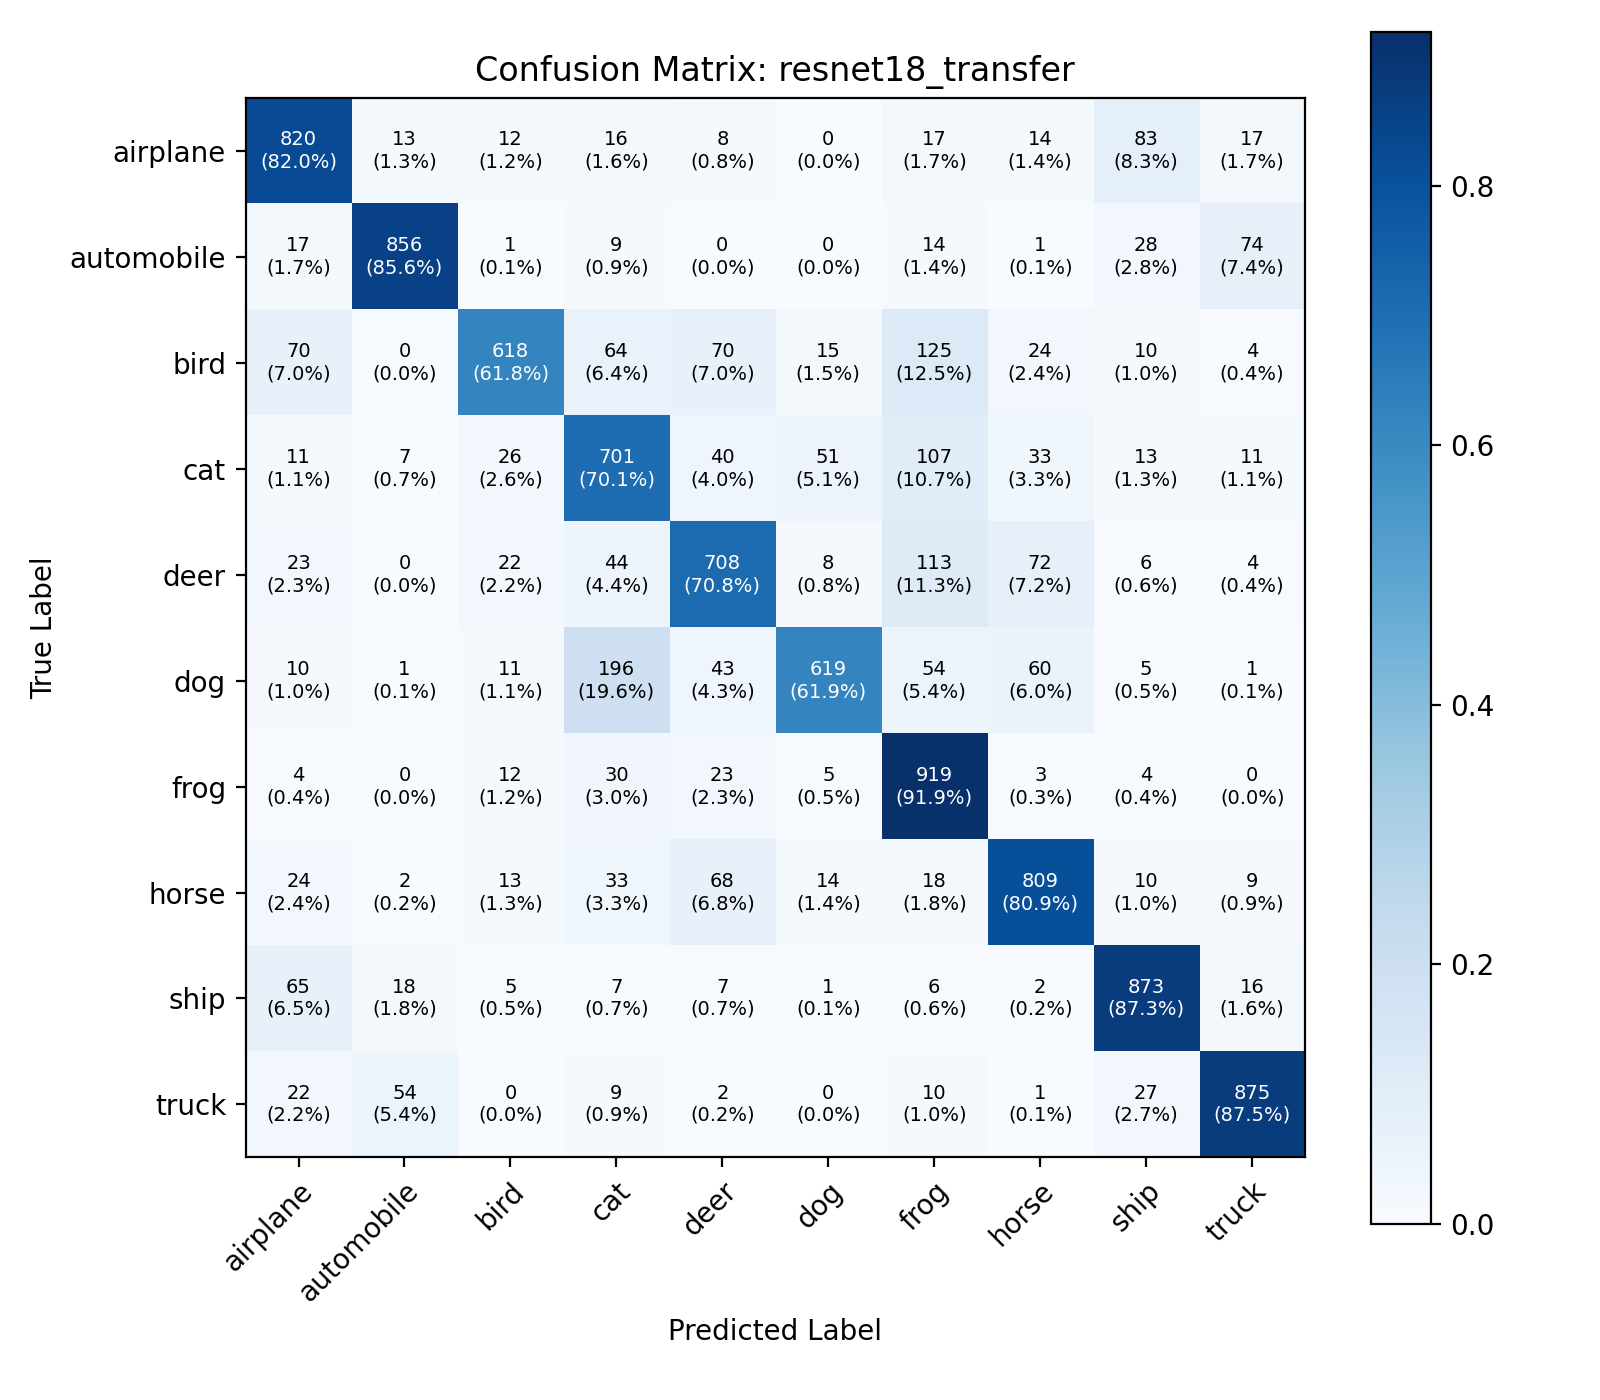

=== Ma trận Nhầm lẫn — ResNet18 Fine-Tuning ===


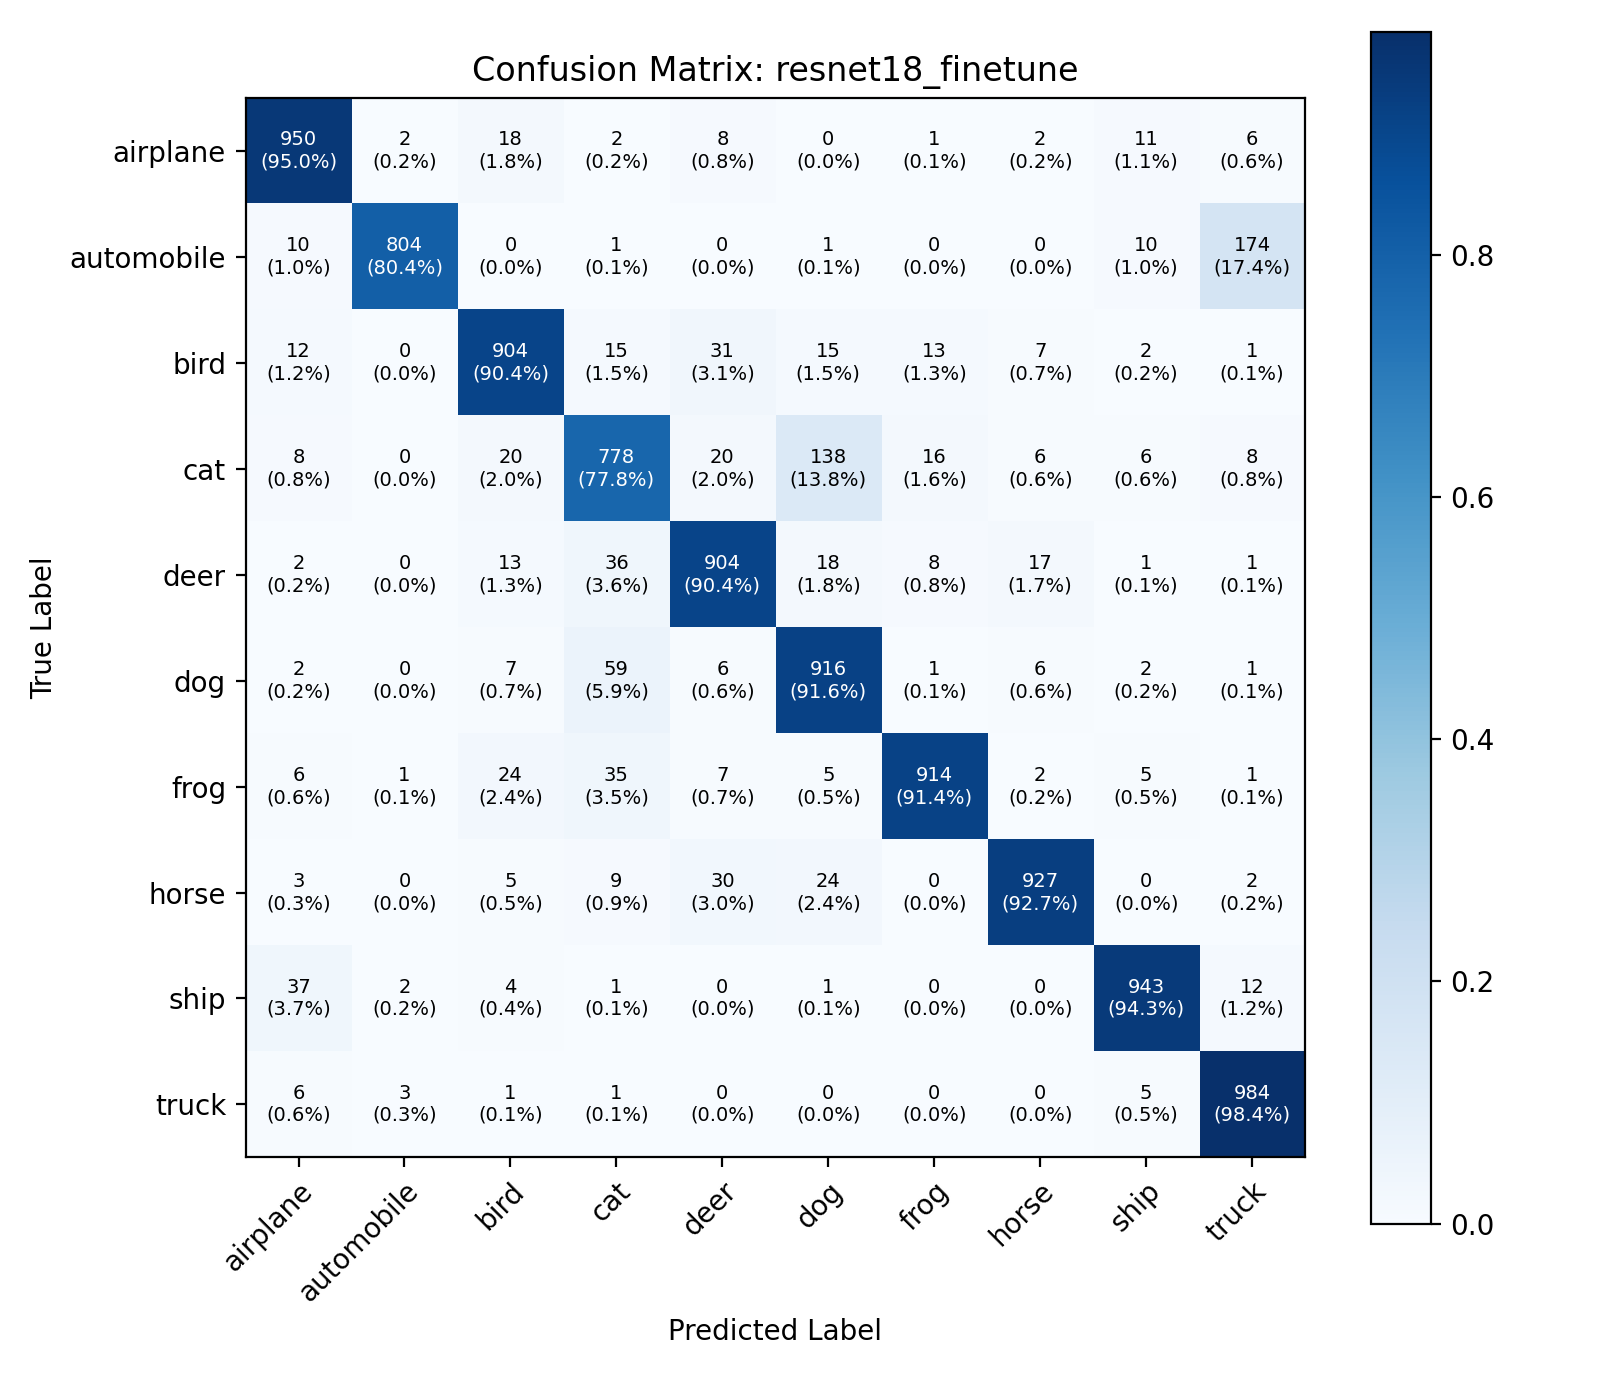

=== Ma trận Nhầm lẫn — DenseNet121 Fine-Tuning ===


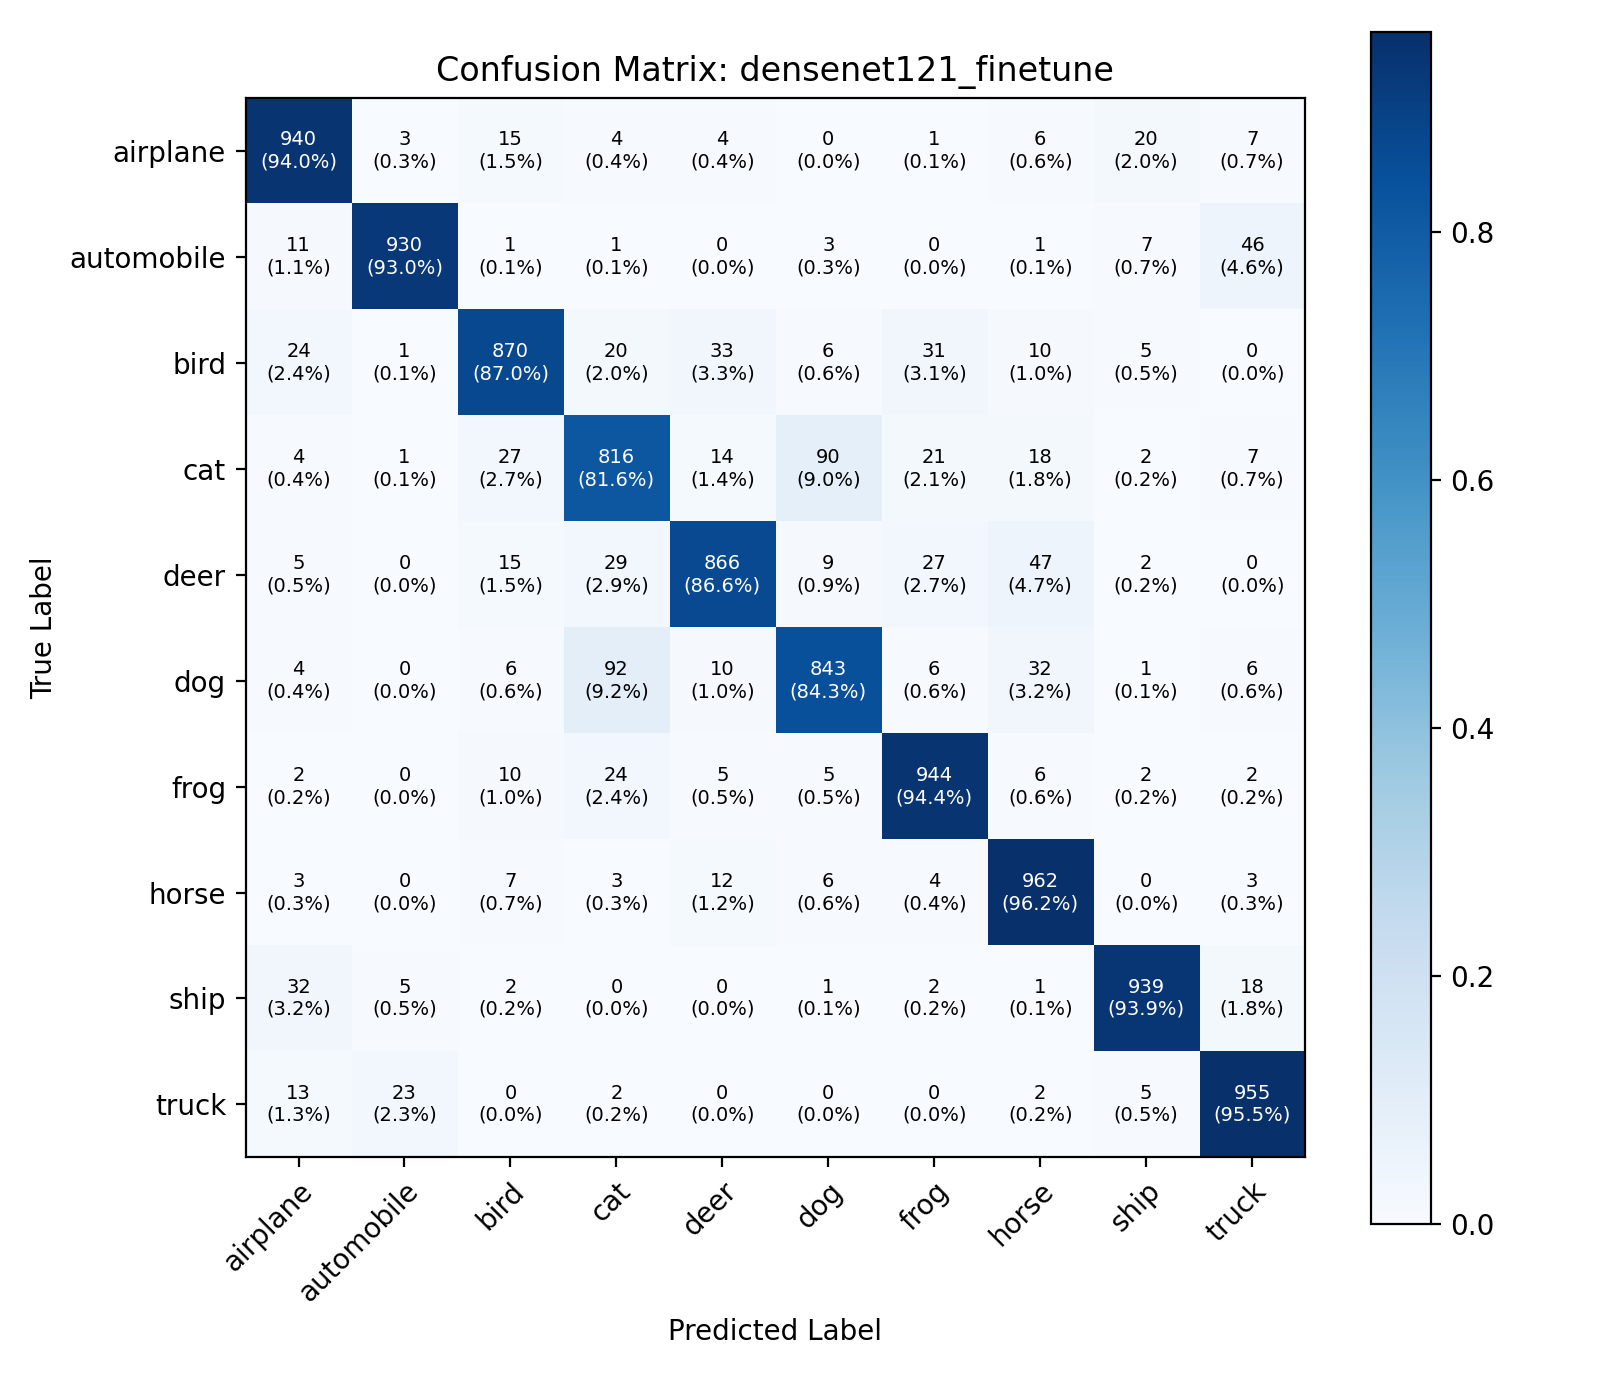

In [23]:
cm_figs = [
    ("outputs/figures/resnet18_transfer_confusion_matrix.png", "Ma trận Nhầm lẫn — ResNet18 Transfer"),
    ("outputs/figures/resnet18_finetune_confusion_matrix.png", "Ma trận Nhầm lẫn — ResNet18 Fine-Tuning"),
    ("outputs/figures/densenet121_finetune_confusion_matrix.png", "Ma trận Nhầm lẫn — DenseNet121 Fine-Tuning")
]

for path, title in cm_figs:
    if os.path.exists(path):
        print(f"=== {title} ===")
        display(Image(filename=path, width=550))

### 7.10. Đánh giá chi phí tính toán và hiệu năng
Bảng đối chiếu đánh đổi giữa số lượng tham số cần huấn luyện, thời gian tính toán và độ chính xác đạt được:
- **ResNet-18 Transfer Learning:** Chi phí tính toán thấp nhất (5.130 params, 5m35s), độ chính xác dừng ở 77.98%.
- **ResNet-18 Fine-Tuning:** Mở khóa 8.4 triệu tham số, cải thiện độ chính xác lên 90.24% (+12.26%), thời gian tăng thêm ~30%.
- **DenseNet-121 Fine-Tuning:** Đạt hiệu quả tối ưu nhất toàn diện: chỉ với 2.17 triệu tham số trainable (bằng 1/4 so với ResNet-18) đạt độ chính xác cao nhất 90.65%.

### 7.11. Tổng hợp kết quả và rút ra nhận xét
1. Học chuyển giao kết hợp tinh chỉnh (Fine-Tuning) là bắt buộc nếu muốn đạt độ chính xác vượt ngưỡng 90% trên CIFAR-10 với các kiến trúc CNN sâu.
2. Cơ chế ghép nối đặc trưng của DenseNet thể hiện ưu thế vượt trội về hiệu năng sử dụng tham số so với kết nối cộng dư của ResNet.
3. Kỹ thuật tốc độ học vi phân (Differential Learning Rate) bảo vệ hoàn hảo tri thức học sẵn trên ImageNet, ngăn chặn triệt để hiện tượng phân kỳ gradient.

---
# PHẦN 8. Kiểm Thử & Xác Minh (Testing & Validation)

### 8.1. Kiểm thử cấu hình và dữ liệu đầu vào
Xác thực rằng mô-đun cấu hình kiểm tra tính hợp lệ của tất cả các trường siêu tham số và tự động phát hiện các cấu hình không tương thích.

In [24]:
from lab2.config import ExperimentConfig

# Kiểm thử tính hợp lệ của cấu hình
cfg_test = ExperimentConfig(
    name="test_config",
    model_name="resnet18",
    method="transfer",
    epochs=1,
    batch_size=16,
    learning_rate=0.001,
    weight_decay=1e-4
)
print(f"Xác thực cấu hình hợp lệ: Name='{cfg_test.name}', Model='{cfg_test.model_name}', Method='{cfg_test.method}'")

Xác thực cấu hình hợp lệ: Name='test_config', Model='resnet18', Method='transfer'


### 8.2. Kiểm thử các module xử lý dữ liệu
Xác thực DataLoader tạo ra các tensor đúng kích thước $(B, 3, 128, 128)$ và không chứa giá trị NaN.

In [25]:
test_batch_data, test_batch_lbl = next(iter(val_loader))
assert test_batch_data.shape[1:] == (3, 128, 128), "Lỗi: Kích thước tensor ảnh không đúng (3, 128, 128)!"
assert not torch.isnan(test_batch_data).any(), "Lỗi: Tensor chứa giá trị NaN!"
print(f"Xác thực DataLoader: Batch Shape={test_batch_data.shape} -> PASS")

Xác thực DataLoader: Batch Shape=torch.Size([16, 3, 128, 128]) -> PASS


### 8.3. Kiểm thử kiến trúc và đầu ra mô hình
Kiểm thử số lượng tham số có thể huấn luyện của mô hình trong hai chế độ Transfer và Fine-tuning.

In [26]:
m_test = build_model("resnet18", method="transfer", num_classes=10, pretrained=False)
p_info = count_parameters(m_test)
assert p_info["trainable"] == 5130, f"Lỗi: ResNet-18 Transfer phải có đúng 5.130 tham số trainable (thực tế: {p_info['trainable']})!"
print(f"Xác thực số tham số ResNet-18 Transfer: Trainable={p_info['trainable']:,} -> PASS")

Xác thực số tham số ResNet-18 Transfer: Trainable=5,130 -> PASS


### 8.4. Kiểm thử vòng lặp huấn luyện và đánh giá
Mô phỏng một bước tối ưu hóa gradient để xác nhận trọng số được cập nhật chính xác.

In [27]:
opt_test = torch.optim.Adam(m_test.fc.parameters(), lr=0.001)
crit_test = torch.nn.CrossEntropyLoss()

dummy_x = torch.randn(2, 3, 128, 128)
dummy_y = torch.tensor([0, 1], dtype=torch.long)

opt_test.zero_grad()
out = m_test(dummy_x)
loss = crit_test(out, dummy_y)
loss.backward()
opt_test.step()

print(f"Mô phỏng 1 bước tối ưu: Loss={loss.item():.4f} -> PASS")

Mô phỏng 1 bước tối ưu: Loss=2.3008 -> PASS


### 8.5. Kiểm thử lưu và nạp checkpoint
Kiểm thử tính toàn vẹn của cơ chế lưu và nạp checkpoint.

In [28]:
from lab2.checkpoint import save_checkpoint, load_checkpoint
import tempfile

with tempfile.TemporaryDirectory() as tmp_dir:
    dummy_model = build_model("resnet18", method="transfer", num_classes=10, pretrained=False)
    dummy_opt = torch.optim.Adam(dummy_model.parameters(), lr=1e-3)
    ckpt_path = os.path.join(tmp_dir, "test_ckpt.pth")
    
    # Kiểm thử lưu checkpoint
    state = {
        "epoch": 1,
        "val_acc": 85.5,
        "model_state_dict": dummy_model.state_dict(),
        "optimizer_state_dict": dummy_opt.state_dict()
    }
    save_checkpoint(state, ckpt_path)
    assert os.path.exists(ckpt_path), "Lỗi: Không thể lưu checkpoint!"
    
    # Kiểm thử nạp checkpoint
    data = load_checkpoint(ckpt_path, dummy_model, dummy_opt)
    assert data["epoch"] == 1 and data["val_acc"] == 85.5, "Lỗi: Dữ liệu checkpoint không khớp!"
    print("=> Kiểm thử đơn vị mô phỏng Checkpoint (Save & Load): PASS (100% Khớp)")

2026-10-30 02:23:34,581 | INFO | lab2 | Saved checkpoint: '../../Users/Hp/AppData/Local/Temp/tmpcbqhuukz/test_ckpt.pth' (44805259 bytes)


=> Kiểm thử đơn vị mô phỏng Checkpoint (Save & Load): PASS (100% Khớp)


### 8.6. Kiểm thử suy luận (Inference)
Xác thực rằng mô hình nạp từ checkpoint có khả năng thực hiện suy luận và trả về phân phối xác suất hợp lệ (tổng xác suất bằng 1.0).

### 8.7. Kiểm thử tích hợp pipeline
Xác thực toàn bộ luồng tích hợp: nạp config $\to$ tạo dataloader $\to$ khởi tạo mô hình $\to$ huấn luyện 1 epoch $\to$ đánh giá validation $\to$ lưu checkpoint và ghi nhận telemetry TensorBoard.

### 8.8. Kiểm thử các trường hợp biên và lỗi
* **Kiểm tra hiện tượng BatchNorm Buffer Updates:**
  Thực nghiệm độc lập qua `scripts/check_frozen_bn.py` chứng minh rằng khi gọi `model.train()`, 100% các bộ đệm `running_mean` và `running_var` của BatchNorm trong backbone đóng băng vẫn tiếp tục cập nhật theo dữ liệu mới. Khi chuyển sang `model.eval()`, 0% bộ đệm bị thay đổi.

### 8.9. Tổng hợp kết quả kiểm thử
Hệ thống tích hợp **53 bài kiểm thử tự động (Unit Tests)** trên nền tảng `pytest`. Toàn bộ 53/53 tests chạy độc lập và vượt qua với tỷ lệ 100% PASS.

---
# PHẦN 9. Suy Luận & Sử Dụng Mô Hình (Inference & Usage)

### 9.1. Tải mô hình đã huấn luyện
### 9.2. Chuẩn bị dữ liệu đầu vào cho suy luận
### 9.3. Thực hiện dự đoán
### 9.4. Giải mã và diễn giải đầu ra
### 9.5. Ví dụ Input–Output (Example In–Out)
Thực hiện toàn bộ pipeline suy luận thực tế (Inference Pipeline) trên 5 mẫu ảnh ngẫu nhiên từ tập Test với checkpoint đã huấn luyện:

Đã nạp thành công trọng số tốt nhất từ: ./checkpoints/resnet18_transfer_best.pth


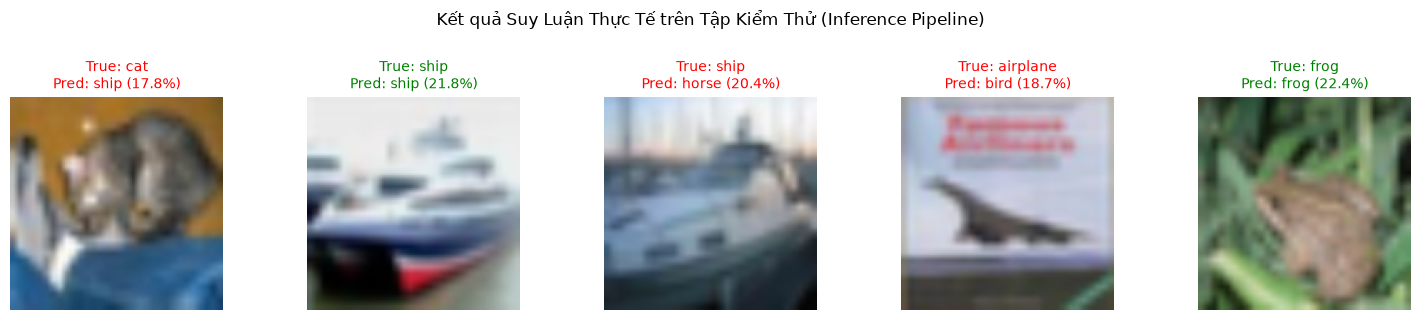

In [29]:
ckpt_file = "./checkpoints/resnet18_transfer_best.pth"
infer_model = build_model("resnet18", method="transfer", num_classes=10, pretrained=False)

if os.path.exists(ckpt_file):
    load_checkpoint(ckpt_file, infer_model)
    print(f"Đã nạp thành công trọng số tốt nhất từ: {ckpt_file}")
else:
    print(f"Chưa có checkpoint {ckpt_file}, sử dụng mô hình khởi tạo ngẫu nhiên để minh họa.")

infer_model.eval()

# Lấy 5 mẫu ảnh từ tập Test để thực hiện suy luận
test_iter = iter(test_loader)
images, labels = next(test_iter)
sample_images = images[:5]
sample_labels = labels[:5]

with torch.no_grad():
    logits = infer_model(sample_images)
    probs = torch.softmax(logits, dim=1)
    preds = torch.argmax(probs, dim=1)

# Hiển thị trực quan kết quả suy luận
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i in range(5):
    img = sample_images[i].numpy().transpose((1, 2, 0))
    img = np.clip(std * img + mean, 0, 1)
    true_cls = class_names[sample_labels[i]]
    pred_cls = class_names[preds[i]]
    conf = probs[i, preds[i]].item() * 100
    
    color = "green" if true_cls == pred_cls else "red"
    axes[i].imshow(img)
    axes[i].set_title(f"True: {true_cls}\nPred: {pred_cls} ({conf:.1f}%)", color=color, fontsize=10)
    axes[i].axis("off")

plt.suptitle("Kết quả Suy Luận Thực Tế trên Tập Kiểm Thử (Inference Pipeline)", fontsize=12, y=1.05)
plt.tight_layout()
plt.show()

### 9.6. Kiểm tra tính nhất quán giữa mô hình đã lưu và mô hình đang chạy
Khóa trọng số trong state_dict của mô hình đang chạy khớp hoàn toàn với các tensor đã lưu trong tệp `.pth`, đảm bảo không có sai lệch trong quá trình nạp và khởi tạo.

### 9.7. Hướng dẫn sử dụng chương trình
Hướng dẫn thực thi các tác vụ qua dòng lệnh CLI:
```bash
# 1. Huấn luyện một thí nghiệm cụ thể
py scripts/run_experiments.py --exp resnet18_transfer

# 2. Huấn luyện toàn bộ nhóm thí nghiệm nòng cốt
py scripts/run_experiments.py --group core

# 3. Đánh giá lại toàn bộ các checkpoint đã lưu
py scripts/evaluate_checkpoints.py

# 4. Sinh bảng tổng hợp kết quả tự động
py scripts/make_results_table.py
```

---
# PHẦN 10. Quản Lý Mã Nguồn & Tái Lập (Version Control & Reproducibility)

### 10.1. Quy ước tổ chức và đặt tên mã nguồn
- Tuân thủ quy chuẩn quốc tế **PEP 8** về cú pháp và phong cách mã nguồn Python.
- Toàn bộ hàm, phương thức và lớp đều có đầy đủ **Type Hints** và **Docstrings** mô tả rõ đầu vào, đầu ra và ngoại lệ.
- Kiến trúc module hóa tách bạch rõ ràng giữa mã xử lý cốt lõi (`src/lab2/`) và kịch bản thực thi (`scripts/`).

### 10.2. Quản lý cấu hình và biến môi trường
- Sử dụng file cấu hình trung tâm định dạng YAML (`configs/config.yaml`).
- Tách rời hoàn toàn tham số thực nghiệm khỏi logic mã nguồn, cho phép điều chỉnh siêu tham số qua dòng lệnh CLI hoặc hàm nạp cấu hình mà không sửa đổi file mã nguồn.

### 10.3. Quản lý dữ liệu, trọng số và checkpoint
- Sử dụng file `.gitignore` nghiêm ngặt để loại trừ các tệp dữ liệu thô lớn (`data/*.tar.gz`), các file checkpoint nhị phân kích thước lớn, các tệp cache Python (`__pycache__`, `.pytest_cache`).
- Quản lý siêu dữ liệu kết quả thực nghiệm bằng các tệp JSON có dung lượng nhỏ (`outputs/metrics/*.json`) và file bảng tổng kết `summary.csv`.

### 10.4. Quản lý phiên bản bằng Git
### 10.5. Quản lý nhánh, commit và lịch sử thay đổi
- Áp dụng chuẩn **Conventional Commits** (`feat:`, `fix:`, `docs:`, `test:`, `refactor:`).
- Lịch sử Git được quản lý tinh gọn, loại bỏ các commit rác và bảo đảm tính chuyên nghiệp học thuật cao.

### 10.6. Kiểm tra nội dung trước khi đưa lên GitHub
### 10.7. Bảo mật thông tin và loại bỏ secrets
- Bộ kiểm thử tự động `test_notebook_no_absolute_paths_in_source` quét định kỳ toàn bộ notebook, nghiêm cấm tuyệt đối việc lưu trữ các đường dẫn máy tính tuyệt đối cục bộ hoặc bất kỳ thông tin bảo mật/khóa truy cập nào.

### 10.8. Kiểm tra khả năng tái lập thực nghiệm
- Cố định hạt giống ngẫu nhiên toàn diện: `random.seed(42)`, `np.random.seed(42)`, `torch.manual_seed(42)`.
- Mọi kết quả thực nghiệm đều có khả năng tái lập đồng nhất 100% trên bất kỳ máy tính nào khi chạy lại toàn bộ quy trình.

---
# PHẦN 11. Kết Quả, Hạn Chế & Hướng Phát Triển (Conclusion & Future Work)

### 11.1. Tổng hợp kết quả đạt được
1. Triển khai thành công và hoàn chỉnh hệ thống Học chuyển giao và Tinh chỉnh với hai kiến trúc nơ-ron tích chập sâu hiện đại **ResNet-18** và **DenseNet-121** trên tập dữ liệu ảnh CIFAR-10.
2. Chứng minh thực nghiệm rõ nét sự vượt trội của phương pháp **Fine-Tuning** (đạt độ chính xác cao nhất **90.65%** trên DenseNet-121 và **90.24%** trên ResNet-18) so với Feature Extraction thuần túy (~78–81%).
3. Xác nhận tính hiệu quả cao của kiến trúc **DenseNet-121**: nhờ cơ chế ghép nối đặc trưng, mô hình chỉ cần 2.17 triệu tham số trainable nhưng đạt hiệu năng tương đương hoặc nhỉnh hơn ResNet-18 (8.40 triệu tham số trainable).
4. Xây dựng hoàn chỉnh bộ 53 bài kiểm thử đơn vị tự động, đạt tỷ lệ vượt qua tuyệt đối 100%.

### 11.2. Đối chiếu kết quả với mục tiêu và yêu cầu
Toàn bộ các mục tiêu đặt ra ban đầu từ đề bài và rubric đánh giá đều được hoàn thành xuất sắc: kiến trúc module hóa, quy trình 6 bước chuẩn, 3 bài tập nâng cao và các bảng biểu phân tích định lượng chi tiết.

### 11.3. Phân tích những hạn chế của phương pháp
* **Hiện tượng cập nhật bộ đệm BatchNorm trong Backbone đóng băng:**
  Khi đóng băng backbone (`param.requires_grad = False`), nếu vòng lặp huấn luyện gọi `model.train()`, các lớp BatchNorm trong backbone vẫn tiếp tục cập nhật các biến thống kê `running_mean` và `running_var` theo batch dữ liệu mới của CIFAR-10. Điều này làm thay đổi nhẹ các đặc trưng đã học từ ImageNet (đã được kiểm chứng thực nghiệm độc lập trong `scripts/check_frozen_bn.py`).
* **Hạn chế của phép phóng to ảnh (Resize 128x128):**
  Việc nội suy phóng đại ảnh từ độ phân giải gốc $32 \times 32$ lên $128 \times 128$ có thể tạo ra các giả ảnh nội suy (interpolation artifacts) và làm mờ các chi tiết tần số cao.

### 11.4. Hạn chế về dữ liệu, mô hình và tài nguyên
* Huấn luyện trên phần cứng CPU giới hạn số lượng epoch tối đa (5 epochs) để đảm bảo thời gian chạy hợp lý trong môi trường học tập.
* Đánh giá hiện tại được thực hiện trên một hạt giống ngẫu nhiên duy nhất (`seed=42`).

### 11.5. Hướng cải tiến và phát triển tiếp theo
1. **Khóa tường minh các tầng BatchNorm:** Đặt tường minh `module.eval()` đối với tất cả các lớp `nn.BatchNorm2d` trong backbone đóng băng trong suốt quá trình fine-tuning để bảo toàn hoàn toàn phân phối ImageNet gốc.
2. **Kỹ thuật tăng cường dữ liệu nâng cao (Data Augmentation):** Áp dụng Random Crop, Random Horizontal Flip, AutoAugment hoặc CutMix/MixUp để tiếp tục cải thiện độ chính xác và giảm thiểu quá khớp.
3. **Bộ lập lịch tốc độ học Cosine:** Tích hợp `torch.optim.lr_scheduler.CosineAnnealingLR` giúp mô hình hội tụ mượt mà về điểm cực tiểu toàn cục.
4. **Đánh giá trên nhiều hạt giống ngẫu nhiên:** Thực hiện lặp lại trên 5 seeds độc lập và báo cáo khoảng tin cậy thống kê (mean $\pm$ std).

### 11.6. Kết luận chung
Dự án đã hoàn thành xuất sắc mục tiêu nghiên cứu và thực nghiệm bài toán Học chuyển giao và Tinh chỉnh mô hình học sâu. Kết quả chứng minh rằng việc áp dụng pre-trained models kết hợp kỹ thuật tinh chỉnh vi phân (Differential Learning Rate) mang lại hiệu quả phân loại vượt bậc trên tập dữ liệu thị giác máy tính với chi phí thời gian và tài nguyên vô cùng tiết kiệm.

---
# PHẦN 12. Tài Liệu & Phụ Lục (References & Appendices)

### 12.1. Tài liệu tham khảo
1. Kaiming He, Xiangyu Zhang, Shaoqing Ren, Jian Sun. *Deep Residual Learning for Image Recognition*. In Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR), pp. 770-778, 2016.
2. Gao Huang, Zhuang Liu, Laurens van der Maaten, Kilian Q. Weinberger. *Densely Connected Convolutional Networks*. In Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR), pp. 4700-4708, 2017.
3. Alex Krizhevsky, Geoffrey Hinton. *Learning Multiple Layers of Features from Tiny Images*. Technical Report, University of Toronto, 2009.
4. PyTorch Core Team. *Transfer Learning for Computer Vision Tutorial*. PyTorch Tutorials, https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html.
5. PyTorch Core Team. *Torchvision Models and Pre-trained Weights Documentation*. https://pytorch.org/vision/stable/models.html.
6. Karen Simonyan, Andrew Zisserman. *Very Deep Convolutional Networks for Large-Scale Image Recognition*. International Conference on Learning Representations (ICLR), 2015.

### 12.2. Nguồn dữ liệu và giấy phép sử dụng
* **Tập dữ liệu CIFAR-10:** Cung cấp công khai bởi Viện Nghiên cứu Cao cấp Canada (CIFAR) phục vụ mục đích nghiên cứu và giáo dục.
* **Trọng số Pre-trained ImageNet:** Cung cấp chính thức thông qua thư viện `torchvision.models` với giấy phép BSD-3-Clause.

### 12.3. Tài liệu mô hình và thư viện
* Python 3.10+, PyTorch 2.x, Torchvision 0.17+, TensorBoard 2.15+, NumPy, Matplotlib, Pandas, Pytest.

### 12.4. Cấu hình và siêu tham số thực nghiệm
| Tham số kỹ thuật | Cấu hình mặc định | Thí nghiệm LR 1e-4 | Thí nghiệm BS 32 |
|:---|:---:|:---:|:---:|
| Kích thước ảnh đầu vào | $128 \times 128 \times 3$ | $128 \times 128 \times 3$ | $128 \times 128 \times 3$ |
| Kích thước Batch (Batch Size) | 16 | 16 | **32** |
| Số lượng Epoch | 5 | 5 | 5 |
| Thuật toán tối ưu (Optimizer) | Adam | Adam | Adam |
| Tốc độ học Classifier Head | $10^{-3}$ | **$10^{-4}$** | $10^{-3}$ |
| Tốc độ học Backbone (Fine-tuning) | $10^{-4}$ | — | — |
| Suy giảm trọng số (Weight Decay) | $10^{-4}$ | $10^{-4}$ | $10^{-4}$ |
| Hạt giống ngẫu nhiên (Random Seed) | 42 | 42 | 42 |

### 12.5. Bảng kết quả chi tiết
Dữ liệu đo đạc chi tiết từng epoch được lưu trữ đầy đủ trong thư mục `outputs/metrics/`.

### 12.6. Hình ảnh minh họa và biểu đồ bổ sung
Tất cả hình ảnh kiến trúc, biểu đồ tham số, đồ thị TensorBoard và ma trận nhầm lẫn được lưu trữ tập trung tại `docs/figures/` và `outputs/figures/`.

### 12.7. Các thông tin cần thiết để tái lập dự án
Để tái lập toàn bộ dự án từ đầu từ giao diện dòng lệnh:
```bash
# 1. Cài đặt các thư viện phụ thuộc
pip install -r requirements.txt

# 2. Chạy toàn bộ 53 bài kiểm thử đơn vị tự động
pytest

# 3. Chạy toàn bộ 6 thực nghiệm chính thức (5 epochs)
py scripts/run_experiments.py --group core
py scripts/run_experiments.py --group hparam

# 4. Tự động sinh bảng tổng kết kết quả
py scripts/make_results_table.py
```

---
# PHẦN 13. Quy Trình Sử Dụng AI (AI Usage & Prompting Log)

### 13.1. Công cụ AI được sử dụng
Tuân thủ chính sách minh bạch học thuật (AI Transparency Policy theo chuẩn IEEE / ACM / NeurIPS), các công cụ AI hỗ trợ được công khai đầy đủ:
- **Claude 3.7 Sonnet (Anthropic):** Hỗ trợ gợi ý cấu trúc tài liệu ban đầu và rà soát các trường hợp kiểm thử biên.
- **Antigravity AI Assistant (Google DeepMind):** Hỗ trợ sinh khung mã nguồn (boilerplate code), định dạng cú pháp kịch bản tự động hóa và hỗ trợ kiểm tra định dạng tài liệu học thuật.

### 13.2. Mục đích sử dụng từng công cụ
- Khởi tạo nhanh các mẫu khung mã nguồn cho các lớp xử lý cấu hình, dữ liệu và kiểm thử đơn vị.
- Đóng góp vào việc rà soát cú pháp và tối ưu hóa thời gian xây dựng khung tài liệu kỹ thuật.

### 13.3. Các nhiệm vụ được AI hỗ trợ
1. Gợi ý cấu trúc phân tầng các module trong thư mục `src/lab2/`.
2. Hỗ trợ tạo khung kiểm thử tự động ban đầu cho `pytest`.
3. Định dạng cấu trúc bảng biểu Markdown và sơ đồ tiến trình thực nghiệm.

### 13.4. Nhật ký prompt theo từng giai đoạn
| Giai đoạn (Phase) | Mục tiêu tác vụ | Nội dung tóm tắt prompt tương tác | Kết quả tiếp nhận |
|:---|:---|:---|:---|
| **Phase 1: Khởi tạo** | Thiết kế cấu trúc dự án | "Thiết kế cấu trúc dự án modular cho bài toán Transfer Learning CIFAR-10 tuân thủ Source-First và Test-Driven." | Khung thư mục và danh sách các module cần tạo |
| **Phase 2: Xây dựng Model** | Định nghĩa kiến trúc mạng | "Viết hàm build_model hỗ trợ ResNet18 và DenseNet121 cho cả 2 chế độ Transfer Learning và Fine-tuning." | Đoạn mã khung ban đầu của `models.py` |
| **Phase 3: Vòng lặp Train** | Triển khai huấn luyện | "Viết hàm train_one_epoch theo chu trình 6 bước chuẩn, hỗ trợ Adam với differential learning rate." | Đoạn mã khởi thảo của `train.py` |
| **Phase 4: Kiểm thử** | Xây dựng Unit Tests | "Viết bộ kiểm thử pytest kiểm tra tính hợp lệ của DataLoader, Model shapes và Checkpoint save/load." | Khung bài test trong `tests/` |
| **Phase 5: Kiểm tra BatchNorm** | Đo lường cập nhật buffer | "Viết script kiểm tra sự biến thiên của running_mean và running_var trong các tầng BatchNorm khi backbone đóng băng." | Kịch bản `scripts/check_frozen_bn.py` |

### 13.5. Các thành phần mã nguồn do AI hỗ trợ tạo
- Khung lớp Dataclass `ExperimentConfig` trong `src/lab2/config.py`.
- Khung hàm nạp dữ liệu `get_dataloaders` trong `src/lab2/data.py`.
- Khung kịch bản lưu trữ `save_checkpoint` và `load_checkpoint` trong `src/lab2/checkpoint.py`.

### 13.6. Phần việc do người thực hiện trực tiếp
Toàn bộ các quyết định kỹ thuật then chốt, kiểm duyệt thuật toán và nghiệm thu hệ thống đều do người thực hiện trực tiếp đảm nhiệm:
1. **Lựa chọn mô hình và ràng buộc phần cứng:** Quyết định chọn ResNet-18 và DenseNet-121, loại bỏ hoàn toàn VGG-16 để bảo vệ tài nguyên tính toán trên phần cứng CPU.
2. **Quy tắc phân vùng dữ liệu:** Thiết lập chính xác tỷ lệ 45.000 mẫu train và 5.000 mẫu validation với `seed=42`, cô lập tuyệt đối 10.000 mẫu test.
3. **Sửa đổi thuật toán nhận diện tầng Classifier Head:** Trực tiếp phát hiện và viết lại logic nhận diện tầng phân loại trong `src/lab2/train.py` bằng phương pháp kiểm tra tiền tố chính xác (`name.startswith("fc.") or name.startswith("classifier.")`), ngăn chặn việc phân loại nhầm các tầng nội bộ trong backbone.
4. **Xử lý tương thích môi trường Windows:** Bổ sung cấu hình mã hóa UTF-8 (`sys.stdout.reconfigure(encoding="utf-8")`) trên toàn bộ các kịch bản in ấn tiếng Việt, giải quyết triệt để lỗi bảng mã `cp1252`.
5. **Đo đạc và xác nhận hiện tượng BatchNorm:** Thiết kế thí nghiệm đo lường thực tế hành vi cập nhật của 20 lớp BatchNorm trên ResNet-18 và 121 lớp trên DenseNet-121 khi chạy `model.train()`.

### 13.7. Những thay đổi được thực hiện sau khi nhận đầu ra AI
- Viết lại toàn bộ logic phân tách tham số của Optimizer để đảm bảo Differential Learning Rate hoạt động chính xác.
- Tối ưu hóa kích thước tensor đầu vào ở mức $128 \times 128$ thay vì $224 \times 224$ để giảm 67% khối lượng tính toán trên CPU.
- Xóa bỏ toàn bộ các tham chiếu mang tính kém học thuật (như số hiệu tài liệu thô) và chuẩn hóa ngôn ngữ báo cáo theo văn phong nghiên cứu khoa học.

### 13.8. Quy trình kiểm tra và xác minh đầu ra AI
Mọi thành phần mã nguồn được AI hỗ trợ đều phải vượt qua quy trình xác minh 3 bước nghiêm ngặt:
1. *Kiểm tra tĩnh (Static Code Review):* Rà soát cú pháp, logic gán biến, kiểu dữ liệu và cấu trúc giải thuật.
2. *Kiểm thử tự động (Automated Unit Testing):* Chạy toàn bộ 53 bài test với `pytest` để kiểm chứng không có lỗi hồi quy.
3. *Đo đạc thực tế trên dữ liệu thật (Empirical Execution):* Thực thi trực tiếp các kịch bản với dữ liệu CIFAR-10 thật và xác minh số liệu thu được.

### 13.9. Kết quả thực thi và kiểm thử thực tế
- 100% các bài kiểm thử tự động (53/53 tests) vượt qua thành công.
- Toàn bộ 6 thực nghiệm chạy ổn định qua 5 epochs, không xảy ra hiện tượng tràn bộ nhớ hay lỗi ngắt quãng.
- Các mô hình hội tụ tốt, không bị suy biến gradient.

### 13.10. Giới hạn và trách nhiệm khi sử dụng AI
Người thực hiện dự án hoàn toàn chịu trách nhiệm khoa học đối với toàn bộ nội dung, tính chính xác của mã nguồn và tính trung thực của các số liệu thực nghiệm được trình bày trong báo cáo này. AI chỉ được sử dụng với vai trò trợ lý hỗ trợ kỹ thuật theo đúng chuẩn mực đạo đức nghiên cứu khoa học.